<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Classification/classification_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Klasifikasi Sikap Publik terhadap AI yang Menggantikan Pekerjaan Manusia Berdasarkan Komentar YouTube**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua - 4.33.24.2.15)
2.   Roihan Saputra (4.33.24.2.20)

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

---
## Gambaran Umum Notebook
Notebook ini melanjutkan tahap *Data Preparation* (Bab 1-5) dan membangun model klasifikasi sikap publik dengan 3 label: **positif**, **negatif**, dan **perlu ditinjau**.

| Bab | Tahap | Isi |
|---|---|---|
| 6 | Text Preprocessing | case folding, removing, filtering (stopword), tokenizing, stemming |
| 7 | Ekstraksi Fitur | pembagian data 80:20 dan embedding e5-large |
| 8 | Klasifikasi | SVM linear dengan pengaturan awal |
| 9 | Optimasi & Evaluasi | Bayesian Search (Optuna), evaluasi metrik, cek overfitting/underfitting, robustness, perbandingan dengan model lain, uji statistik McNemar, serta analisis per bahasa, analisis kesalahan, uji dengan label manusia, serta menyimpan model |
| 10 | Kesimpulan | hasil akhir, keterbatasan, dan rekomendasi |

**Model akhir:** embedding **e5-large** + **SVM linear**, di-*tuning* dengan Bayesian Search. Model ini dipilih karena paling seimbang antara **skor**, **good fit** (tidak overfitting), dan **robust** (stabil, termasuk pada video yang belum pernah dilihat), sehingga cocok untuk otomasi pelabelan komentar baru.

# **1. Import Library & Setup Environment**

Seluruh library untuk preprocessing teks, ekstraksi fitur, klasifikasi, dan optimasi disiapkan di sel ini. Semua sumber acak dikunci dengan angka **42** (`random_state=42`) agar hasil dapat direproduksi.

In [1]:
# Pasang library yang belum ada (Google Colab / Antigravity)
%pip install Sastrawi nltk sentence-transformers optuna scikit-learn scipy matplotlib torch --quiet

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Text preprocessing (Bab 6)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Ekstraksi fitur dan pembagian data (Bab 7)
import torch
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split

# Klasifikasi (Bab 8)
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score

# Optimasi dan evaluasi (Bab 9)
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from scipy.sparse import hstack, csr_matrix
from scipy.stats import binomtest

# Menyimpan model (Bab 9.8)
import joblib

In [3]:
# Kunci semua sumber acak dengan angka 42 supaya hasilnya selalu sama
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Pakai GPU kalau ada (lebih cepat untuk e5-large)
perangkat = "cuda" if torch.cuda.is_available() else "cpu"
print("Perangkat:", perangkat)

Perangkat: cuda


# **6. Text Preprocessing**

Bab 3 hanya membersihkan data mentah. Bab ini mengolah **teks komentar** dengan urutan:

**6.2 case folding → 6.3 removing → 6.4 filtering (stopword) → 6.5 tokenizing → 6.6 stemming**

Hasil olahan disimpan di kolom baru `teks` (dan `token`). Kolom `teks` dipakai oleh **TF-IDF pada model pembanding** (Bab 9.5). Model akhir memakai embedding e5-large yang membaca kolom `comment` (teks asli), karena e5 memahami kalimat utuh termasuk tanda baca, huruf besar, dan kata sambung. Bab ini juga menentukan **baris data yang dipakai**: komentar yang kosong setelah stopword dibuang (6.4) tidak ikut dimodelkan.

## **6.1 Memuat Data Berlabel**

**Sel ini:** memuat data berlabel hasil Bab 5 (`youtube_comments_label_final.csv`) langsung dari **GitHub**, jadi notebook bisa dijalankan di **Google Colab** maupun **Antigravity** tanpa upload file (butuh koneksi internet). Lalu ditampilkan jumlah komentar dan sebaran labelnya.

In [4]:
# Dataset diambil langsung dari GitHub,
# jadi bisa dipakai di Google Colab maupun Antigravity tanpa upload file (butuh internet)
url = "https://raw.githubusercontent.com/RoihansLab/Data-Mining-Project/main/datasets/youtube_comments_label_final.csv"

df = pd.read_csv(url)
df.head()

,video_title,comment,likes,author_id,bahasa,label,sumber_label
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0,Indonesia,perlu ditinjau,claude
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1,Indonesia,negatif,claude
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2,Indonesia,negatif,manual
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3,Indonesia,negatif,claude
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,4,Indonesia,negatif,claude


In [5]:
print("Jumlah komentar:", len(df))
print("Nilai kosong   :", df.isnull().sum().sum())

Jumlah komentar: 3935
Nilai kosong   : 0


In [6]:
df["label"].value_counts()

,count
label,
perlu ditinjau,2342
negatif,938
positif,655


**Hasil:**

- Ada **3.935 komentar** dan 7 kolom, **tidak ada nilai kosong**.
- Kolom yang dipakai: `comment` (teks asli), `bahasa` (untuk stemming), dan `label` (jawaban). Kolom `sumber_label` hanya mencatat asal label (manual atau Claude).
- Sebaran label: perlu ditinjau 2.342 (59,5%), negatif 938 (23,8%), positif 655 (16,6%). Labelnya **tidak seimbang**, jadi model memakai `class_weight="balanced"` dan dinilai dengan **macro-F1**.

**Grafik: sebaran label.** Lingkaran menunjukkan porsi setiap label dari seluruh 3.935 komentar.

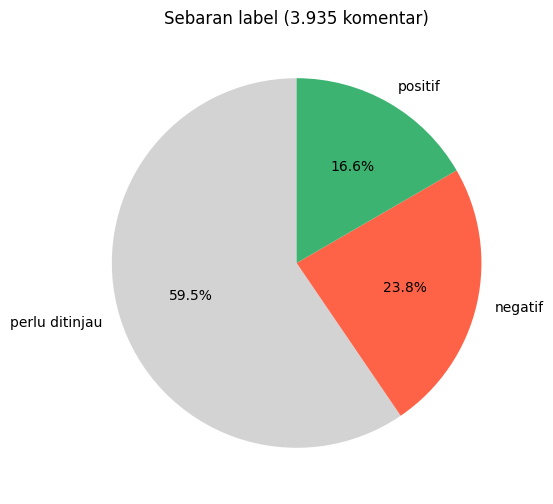

In [7]:
jumlah_label = df["label"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(jumlah_label.values, labels=jumlah_label.index, autopct="%.1f%%", startangle=90,
        colors=["lightgray", "tomato", "mediumseagreen"])
plt.title("Sebaran label (3.935 komentar)")
plt.show()

**Komentar dengan *likes* terbanyak per label.** Fungsi `top_likes` mengambil 10 komentar dengan *likes* terbanyak dari satu label, lalu menggambarnya dari yang paling populer (atas) ke bawah. Komentar populer penting dilihat, karena mewakili pendapat yang paling banyak disetujui penonton.

**Sel ini:** membuat fungsi `top_likes`.

In [8]:
def top_likes(nama_label, warna):
    # 1. Ambil 10 komentar dengan likes terbanyak dari label ini
    top = df[df["label"] == nama_label].nlargest(10, "likes")

    # 2. Gambar dari yang paling populer (atas) ke bawah
    plt.figure(figsize=(10, 5))
    plt.barh(range(len(top)), top["likes"], color=warna)
    plt.yticks(range(len(top)), top["comment"].str[:60])   # potong komentar supaya muat
    plt.gca().invert_yaxis()
    plt.xlabel("Jumlah likes")
    plt.title("10 komentar " + nama_label + " dengan likes terbanyak")
    plt.show()

    return top[["comment", "likes", "video_title", "bahasa"]]

**Sel ini:** 10 komentar **positif** dengan *likes* terbanyak.

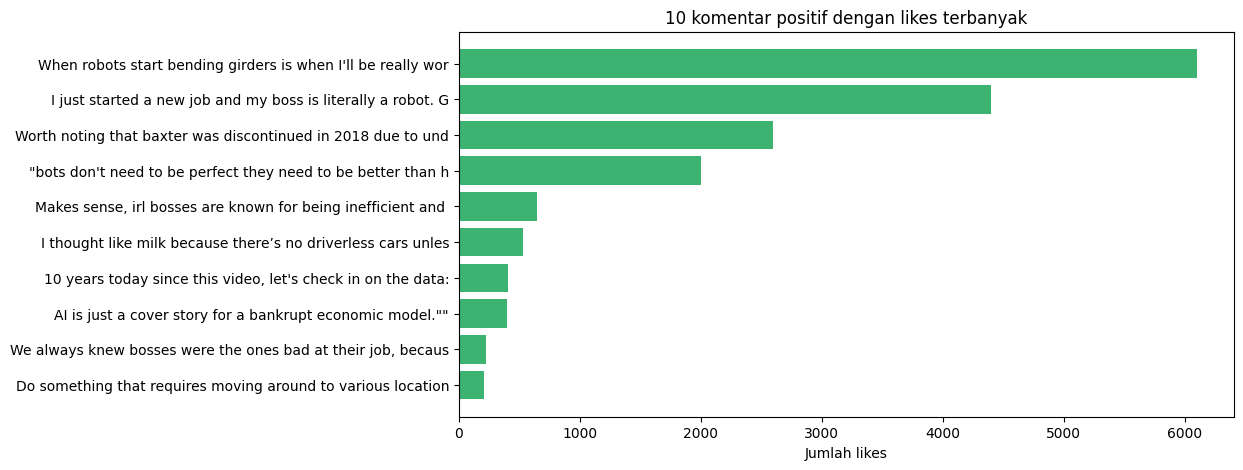

,comment,likes,video_title,bahasa
1888,When robots start bending girders is when I'll...,6100,Humans Need Not Apply - CGP Grey,Inggris
1483,I just started a new job and my boss is litera...,4400,Humans Need Not Apply - CGP Grey,Inggris
1480,Worth noting that baxter was discontinued in 2...,2600,Humans Need Not Apply - CGP Grey,Inggris
2514,"""bots don't need to be perfect they need to be...",2000,Humans Need Not Apply - CGP Grey,Inggris
1783,"Makes sense, irl bosses are known for being in...",650,Humans Need Not Apply - CGP Grey,Inggris
1557,I thought like milk because there’s no driverl...,527,Humans Need Not Apply - CGP Grey,Inggris
2505,"10 years today since this video, let's check i...",406,Humans Need Not Apply - CGP Grey,Inggris
2952,AI is just a cover story for a bankrupt econom...,398,UK unemployment soars: is AI already taking ou...,Inggris
1784,We always knew bosses were the ones bad at the...,224,Humans Need Not Apply - CGP Grey,Inggris
2150,Do something that requires moving around to va...,209,Humans Need Not Apply - CGP Grey,Inggris


In [9]:
top_likes("positif", "mediumseagreen")

**Sel ini:** 10 komentar **negatif** dengan *likes* terbanyak.

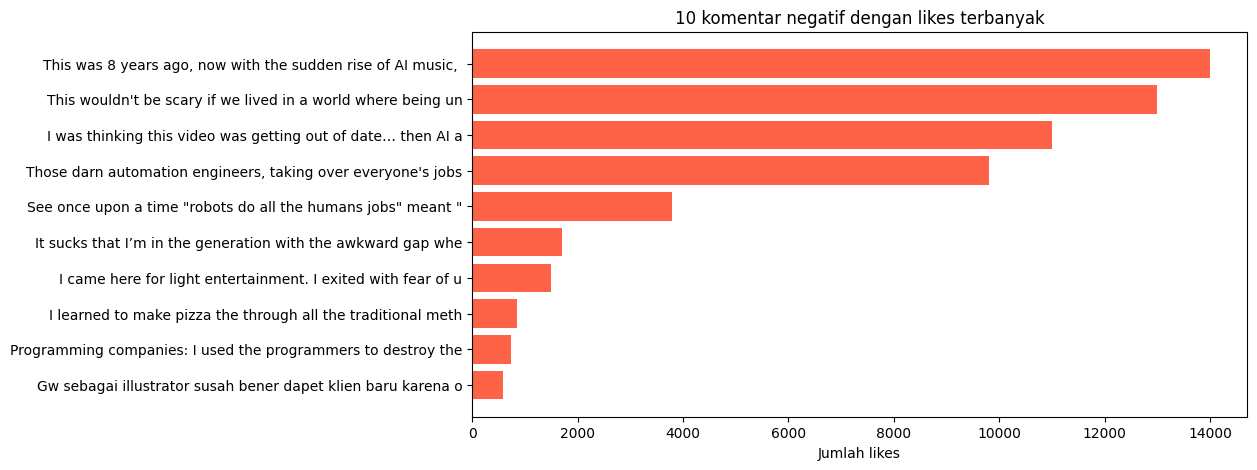

,comment,likes,video_title,bahasa
1474,"This was 8 years ago, now with the sudden rise...",14000,Humans Need Not Apply - CGP Grey,Inggris
1470,This wouldn't be scary if we lived in a world ...,13000,Humans Need Not Apply - CGP Grey,Inggris
1468,I was thinking this video was getting out of d...,11000,Humans Need Not Apply - CGP Grey,Inggris
1487,"Those darn automation engineers, taking over e...",9800,Humans Need Not Apply - CGP Grey,Inggris
1473,"See once upon a time ""robots do all the humans...",3800,Humans Need Not Apply - CGP Grey,Inggris
1874,It sucks that I’m in the generation with the a...,1700,Humans Need Not Apply - CGP Grey,Inggris
2502,I came here for light entertainment. I exited ...,1500,Humans Need Not Apply - CGP Grey,Inggris
1484,I learned to make pizza the through all the tr...,844,Humans Need Not Apply - CGP Grey,Inggris
1841,Programming companies: I used the programmers ...,741,Humans Need Not Apply - CGP Grey,Inggris
3,Gw sebagai illustrator susah bener dapet klien...,588,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Indonesia


In [10]:
top_likes("negatif", "tomato")

**Sel ini:** 10 komentar **perlu ditinjau** dengan *likes* terbanyak. Komentar ini perlu **ditinjau lebih serius**, karena paling banyak disukai penonton tetapi sikapnya tidak jelas.

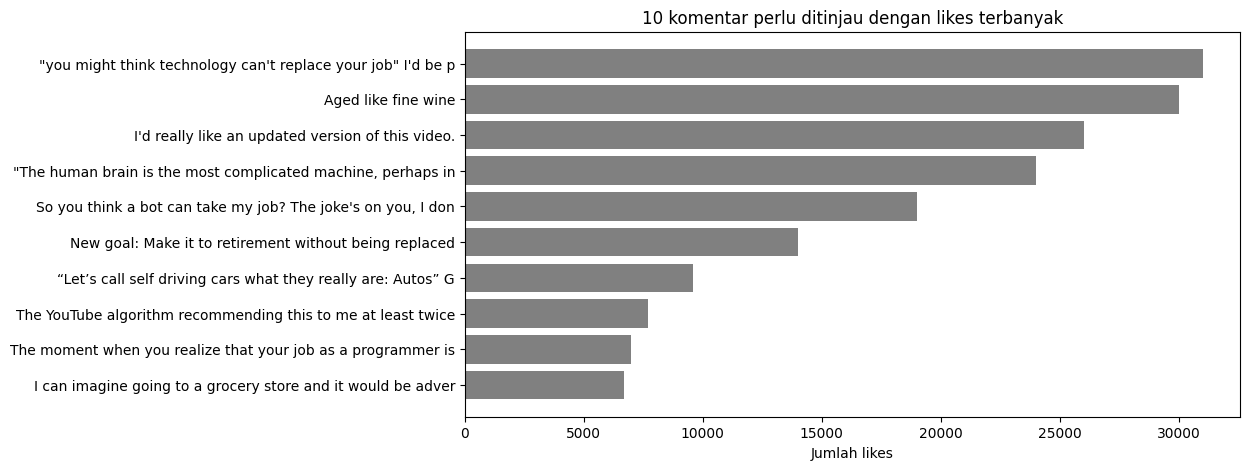

,comment,likes,video_title,bahasa
1478,"""you might think technology can't replace your...",31000,Humans Need Not Apply - CGP Grey,Inggris
1471,Aged like fine wine,30000,Humans Need Not Apply - CGP Grey,Inggris
1871,I'd really like an updated version of this video.,26000,Humans Need Not Apply - CGP Grey,Inggris
1482,"""The human brain is the most complicated machi...",24000,Humans Need Not Apply - CGP Grey,Inggris
1873,So you think a bot can take my job? The joke's...,19000,Humans Need Not Apply - CGP Grey,Inggris
1884,New goal: Make it to retirement without being ...,14000,Humans Need Not Apply - CGP Grey,Inggris
1875,“Let’s call self driving cars what they really...,9600,Humans Need Not Apply - CGP Grey,Inggris
1479,The YouTube algorithm recommending this to me ...,7700,Humans Need Not Apply - CGP Grey,Inggris
1880,The moment when you realize that your job as a...,7000,Humans Need Not Apply - CGP Grey,Inggris
1477,I can imagine going to a grocery store and it ...,6700,Humans Need Not Apply - CGP Grey,Inggris


In [11]:
top_likes("perlu ditinjau", "gray")

**Hasil:**

- Label **perlu ditinjau** paling banyak (59,5%), disusul **negatif** (23,8%) dan **positif** (16,6%).
- **Positif terpopuler:** *"When robots start bending girders is when I'll be really worried."* (6.100 *likes*), disusul komentar bahwa bos berupa robot justru bos terbaik (4.400 *likes*). Sikap positif yang populer biasanya **meremehkan ancaman AI dengan nada santai**.
- **Negatif terpopuler:** *"This was 8 years ago, now with the sudden rise of AI music, AI art, AI video, ChatGPT..."* (14.000 *likes*) dan *"This wouldn't be scary if we lived in a world where being unemployed didn't mean loss of livelihood"* (13.000 *likes*). Kekhawatiran yang populer adalah **AI ternyata berkembang lebih cepat dari dugaan** dan **takut kehilangan penghasilan**.
- **Perlu ditinjau terpopuler** justru punya *likes* paling besar: *"I'd be pretty horrified if technology started replacing unemployed peoples jobs"* (31.000 *likes*), *"Aged like fine wine"* (30.000), dan *"New goal: Make it to retirement without being replaced"* (14.000). Sebagian besar berupa **sindiran atau candaan yang diam-diam menyiratkan kekhawatiran** (misalnya "Aged like fine wine" berarti prediksi video tentang AI menggantikan pekerjaan ternyata terbukti). Karena aturan pelabelan memasukkan sindiran yang arahnya tidak jelas ke "perlu ditinjau", komentar-komentar inilah yang **paling layak ditinjau ulang secara manual**: bila sindiran seperti ini dihitung negatif, porsi kekhawatiran publik kemungkinan lebih besar dari 23,8%.
- Hampir semua komentar terpopuler berbahasa Inggris dan berasal dari video CGP Grey, yang sudah ditonton bertahun-tahun sehingga mengumpulkan *likes* jauh lebih banyak.

## **6.2 Case Folding**

Semua huruf diubah menjadi huruf kecil, supaya "AI", "Ai", dan "ai" dianggap kata yang sama.

**Sel ini:** mengubah kolom `comment` menjadi huruf kecil dan menyimpannya di kolom `teks`.

In [12]:
# 1. Ubah semua huruf menjadi huruf kecil, simpan di kolom baru 'teks'
df["teks"] = df["comment"].str.lower()

# 2. Hitung komentar yang tadinya punya huruf besar
huruf_besar = df["comment"] != df["teks"]
print("Komentar yang tadinya punya huruf besar:", huruf_besar.sum())

Komentar yang tadinya punya huruf besar: 3414


In [13]:
df[["comment", "teks"]].head()

,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang ke spanyol d...
1,Menurut saya jika semua pengusaha berpikiran s...,menurut saya jika semua pengusaha berpikiran s...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur ya sebagai seorang yang bekerja di bidan...
3,Gw sebagai illustrator susah bener dapet klien...,gw sebagai illustrator susah bener dapet klien...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung -> efesiensi phk->produksi meningk...


**Hasil:** 3.414 dari 3.935 komentar punya huruf besar, dan sekarang semuanya sudah menjadi huruf kecil di kolom `teks`.

## **6.3 Removing**

Membuang bagian teks yang tidak dipakai TF-IDF, lalu merapikan spasi:

| Yang dibuang | Pola (regex) | Contoh |
|---|---|---|
| URL | `https?://\S+` atau `www.\S+` | `https://youtu.be/...` |
| semua karakter selain huruf a-z dan spasi | `[^a-z\s]` | angka `2030`, tanda baca `?!.,`, emoji 😭, simbol `#` |
| spasi berlebih | dipecah per kata lalu digabung dengan satu spasi | `"ai   bodoh"` → `"ai bodoh"` |

Karakter yang dibuang diganti spasi (bukan dihapus), supaya kata tidak menempel, misalnya `"ai,robot"` menjadi `"ai robot"`, bukan `"airobot"`.

**Sel ini:** membersihkan teks, lalu mengecek jumlah komentar yang masih mengandung karakter selain huruf dan spasi (harus 0).

In [14]:
# Pola karakter yang dibuang: semua karakter selain huruf a-z dan spasi
pola_bukan_huruf = r"[^a-z\s]"

print("Komentar berisi angka/tanda baca/emoji/simbol:", df["teks"].str.contains(pola_bukan_huruf).sum())

Komentar berisi angka/tanda baca/emoji/simbol: 3456


In [15]:
# 1. Buang URL
df["teks"] = df["teks"].str.replace(r"https?://\S+|www\.\S+", " ", regex=True)

# 2. Buang angka, tanda baca, emoji, dan simbol (diganti spasi supaya kata tidak menempel)
df["teks"] = df["teks"].str.replace(pola_bukan_huruf, " ", regex=True)

# 3. Rapikan spasi berlebih
df["teks"] = df["teks"].str.split().str.join(" ")

In [16]:
print("Sisa komentar berisi angka/tanda baca/emoji/simbol:", df["teks"].str.contains(pola_bukan_huruf).sum())
print("Komentar yang menjadi kosong:", (df["teks"] == "").sum())

df[["comment", "teks"]].head()

Sisa komentar berisi angka/tanda baca/emoji/simbol: 0
Komentar yang menjadi kosong: 0


,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang ke spanyol d...
1,Menurut saya jika semua pengusaha berpikiran s...,menurut saya jika semua pengusaha berpikiran s...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur ya sebagai seorang yang bekerja di bidan...
3,Gw sebagai illustrator susah bener dapet klien...,gw sebagai illustrator susah bener dapet klien...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung efesiensi phk produksi meningkat t...


**Hasil:** sebelum dibersihkan, **3.456 komentar** mengandung angka, tanda baca, emoji, atau simbol. Sesudah dibersihkan, jumlahnya **0**, dan tidak ada komentar yang menjadi kosong.

## **6.4 Filtering (Stopword Removal)**

Membuang kata umum yang tidak membawa makna, misalnya "yang", "dan", "the", "is". Daftarnya gabungan stopword bahasa Indonesia (Sastrawi) dan bahasa Inggris (scikit-learn).

**Kata negasi tetap disimpan**, karena membalik makna kalimat: "AI **tidak** akan menggantikan pekerjaan" berbeda jauh dengan "AI akan menggantikan pekerjaan".

**Sel ini:** menyusun daftar stopword tanpa kata negasi, membuang stopword dari setiap komentar, lalu membuang komentar yang menjadi kosong.

In [17]:
# 1. Kata negasi tetap disimpan karena membalik makna kalimat
negasi = {"tidak", "belum", "nggak", "not", "no", "nor", "never", "nothing", "none", "cannot"}

# 2. Gabungkan stopword Indonesia (Sastrawi) dan Inggris (scikit-learn), lalu keluarkan kata negasi
stopword_indonesia = set(StopWordRemoverFactory().get_stop_words())
stopword_inggris = set(ENGLISH_STOP_WORDS)
stopword = (stopword_indonesia | stopword_inggris) - negasi

print("Jumlah stopword:", len(stopword))

Jumlah stopword: 431


In [18]:
def buang_stopword(teks):
    kata_tersisa = []
    for kata in teks.split():
        if kata not in stopword:
            kata_tersisa.append(kata)
    return " ".join(kata_tersisa)


rata_sebelum = df["teks"].str.split().str.len().mean()
df["teks"] = df["teks"].apply(buang_stopword)
rata_sesudah = df["teks"].str.split().str.len().mean()

print("Rata-rata kata per komentar sebelum:", round(rata_sebelum, 1))
print("Rata-rata kata per komentar sesudah:", round(rata_sesudah, 1))

Rata-rata kata per komentar sebelum: 30.9
Rata-rata kata per komentar sesudah: 18.0


In [19]:
# Komentar yang isinya stopword semua menjadi kosong, jadi dibuang
print("Komentar kosong:", (df["teks"] == "").sum())

df = df[df["teks"] != ""].reset_index(drop=True)
print("Sisa data:", len(df))

Komentar kosong: 8
Sisa data: 3927


**Hasil:**

- Ada 431 stopword. Rata-rata komentar menyusut dari 30,9 kata menjadi 18,0 kata (sekitar 42% kata terbuang).
- 8 komentar menjadi kosong karena isinya stopword semua (misalnya "Indeed, it was" dan "Been there, done that."), jadi dibuang. **Sisa data: 3.927 komentar.**

## **6.5 Tokenizing**

Memecah setiap komentar menjadi daftar kata (token). Contoh: `"ai tidak butuh makan"` → `["ai", "tidak", "butuh", "makan"]`.

**Sel ini:** memecah teks menjadi token di kolom `token`, lalu menghitung jumlah token dan kata unik.

In [20]:
df["token"] = df["teks"].str.split()
df[["teks", "token"]].head()

,teks,token
0,bahas imigrant maroko yg nyebrang spanyol donk...,"[bahas, imigrant, maroko, yg, nyebrang, spanyo..."
1,semua pengusaha berpikiran sama mengganti manu...,"[semua, pengusaha, berpikiran, sama, mengganti..."
2,jujur seorang bekerja bidang desain seni ilust...,"[jujur, seorang, bekerja, bidang, desain, seni..."
3,gw illustrator susah bener dapet klien baru or...,"[gw, illustrator, susah, bener, dapet, klien, ..."
4,niat untung efesiensi phk produksi meningkat t...,"[niat, untung, efesiensi, phk, produksi, menin..."


In [21]:
semua_token = []
for token in df["token"]:
    semua_token.extend(token)

print("Jumlah token    :", len(semua_token))
print("Jumlah kata unik:", len(set(semua_token)))

Jumlah token    : 70745
Jumlah kata unik: 13629


**Hasil:** 3.927 komentar dipecah menjadi **70.745 token** dengan **13.629 kata unik**.

## **6.6 Stemming**

Mengubah setiap kata ke bentuk dasarnya, supaya kata yang maknanya sama dihitung sebagai satu kata. Contoh: "pengusaha" → "usaha", "mengganti" → "ganti", "approaching" → "approach".

Stemmer dipilih sesuai bahasa komentar: **Sastrawi** untuk bahasa Indonesia dan **Porter** untuk bahasa Inggris. Proses ini sekitar 2-3 menit.

**Sel ini:** menjalankan stemming per kata sesuai bahasa komentar, lalu menyusun ulang kolom `teks` dari token hasil stemming.

In [22]:
stem_indonesia = StemmerFactory().create_stemmer()   # Sastrawi untuk bahasa Indonesia
stem_inggris = PorterStemmer()                       # Porter untuk bahasa Inggris


def stemming(token, bahasa):
    hasil = []
    for kata in token:
        if bahasa == "Indonesia":
            hasil.append(stem_indonesia.stem(kata))
        else:
            hasil.append(stem_inggris.stem(kata))
    return hasil

In [23]:
# Stemming setiap komentar sesuai bahasanya (sekitar 2-3 menit)
token_baru = []
for token, bahasa in zip(df["token"], df["bahasa"]):
    token_baru.append(stemming(token, bahasa))

df["token"] = token_baru
df["teks"] = df["token"].str.join(" ")   # teks akhir untuk TF-IDF (dipakai model pembanding di Bab 9.5)
df[["comment", "teks"]].head()

,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang spanyol donk...
1,Menurut saya jika semua pengusaha berpikiran s...,semua usaha pikir sama ganti manusia ai potong...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur orang kerja bidang desain seni ilustrato...
3,Gw sebagai illustrator susah bener dapet klien...,gw illustrator susah bener dapet klien baru or...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung efesiensi phk produksi tingkat tid...


In [24]:
kata_unik = set()
for token in df["token"]:
    kata_unik.update(token)

print("Kata unik setelah stemming:", len(kata_unik))

Kata unik setelah stemming: 9848


**Hasil:** jumlah kata unik turun dari 13.629 menjadi **9.848** (sekitar 28% lebih sedikit), karena kata-kata berimbuhan digabung ke kata dasarnya. Contoh: "semua pengusaha berpikiran sama mengganti manusia" → "semua usaha pikir sama ganti manusia".

Catatan: stemmer bahasa Inggris (Porter) kadang menghasilkan potongan yang bukan kata utuh, misalnya "replacing" → "replac". Ini wajar, karena yang penting kata-kata sejenis menjadi sama.

# **7. Ekstraksi Fitur**

Model tidak bisa membaca kata, jadi setiap komentar diubah menjadi deretan angka (fitur). Model akhir memakai **embedding e5-large**: setiap komentar diubah menjadi 1.024 angka yang mewakili makna kalimatnya.

Urutannya: 7.1 embedding e5-large → 7.2 pembagian data latih dan uji.

## **7.1 Embedding e5-large**

**multilingual-e5-large** adalah model embedding yang sudah dilatih dari jutaan kalimat dalam banyak bahasa (termasuk Indonesia dan Inggris). Setiap komentar diubah menjadi **1.024 angka** yang mewakili makna seluruh kalimat, sehingga komentar yang maknanya mirip punya angka yang mirip walaupun kata-katanya berbeda. Contohnya, "takut kerjaan diambil AI" dan "worried AI will take my job" letaknya berdekatan.

- Masukannya kolom `comment` (teks asli).
- e5 mewajibkan awalan `"query: "` pada setiap teks.
- e5 **tidak dilatih ulang** (hanya dipakai), jadi semua komentar boleh diubah sekaligus tanpa membocorkan informasi data uji. Prosesnya sekitar 2-3 menit di GPU (lebih lama di CPU).

**Sel ini:** memuat e5-large dan mengubah setiap komentar menjadi 1.024 angka (disimpan di `X`), lalu menyimpan label di `y`.

In [25]:
# 1. Muat model e5-large
e5 = SentenceTransformer("intfloat/multilingual-e5-large", device=perangkat)

# 2. e5 mewajibkan awalan "query: " di depan setiap komentar
kalimat = ("query: " + df["comment"]).tolist()

# 3. Ubah setiap komentar menjadi 1.024 angka
X = e5.encode(kalimat, batch_size=16, normalize_embeddings=True, show_progress_bar=True)
X.shape

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/160k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/201 [00:00<?, ?B/s]

Batches:   0%|          | 0/246 [00:00<?, ?it/s]

(3927, 1024)

In [26]:
y = df["label"].to_numpy()
y

array(['perlu ditinjau', 'negatif', 'negatif', ..., 'negatif', 'positif',
       'negatif'], dtype=object)

## **7.2 Pembagian Data Latih dan Uji**

Data dibagi menjadi **80% data latih** dan **20% data uji**, dengan proporsi ketiga label yang sama (`stratify`). Model hanya belajar dari data latih, supaya data uji benar-benar belum pernah dilihat. Embedding e5-large di 7.1 tidak belajar dari data (hanya dipakai), jadi membuat embedding sebelum data dibagi tidak membocorkan informasi data uji.

**Sel ini:** membagi fitur `X`, label `y`, dan tabel `df` sekaligus menjadi `X_train`, `X_test`, `y_train`, `y_test`, `df_train`, dan `df_test`.

In [27]:
# Bagi fitur (X), label (y), dan tabel (df) sekaligus, supaya barisnya tetap berpasangan
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X,
    y,
    df,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji  :", len(X_test))

Jumlah data latih: 3141
Jumlah data uji  : 786


In [28]:
pd.DataFrame({
    "latih": df_train["label"].value_counts(),
    "uji": df_test["label"].value_counts(),
})

,latih,uji
label,,
perlu ditinjau,1867,467
negatif,750,188
positif,524,131


**Hasil:** data latih **3.141 komentar** dan data uji **786 komentar**, dengan proporsi label yang sama:

| Label | Latih | Uji |
|---|---|---|
| perlu ditinjau | 1.867 | 467 |
| negatif | 750 | 188 |
| positif | 524 | 131 |

# **8. Klasifikasi (SVM Linear)**

**SVM (Support Vector Machine) linear** mencari garis pemisah (*hyperplane*) terbaik antar-label di ruang 1.024 angka e5-large, dengan jarak (*margin*) selebar mungkin dari komentar-komentar terdekat. Margin yang lebar membuat model tidak terlalu menghafal data latih, sehingga cocok untuk fitur embedding yang padat seperti e5-large. Untuk 3 label, SVM membuat satu pemisah untuk setiap label (*one-vs-rest*).

Pengaturan awal:
- `C=1`: seberapa ketat model mengikuti data latih (kecil = margin lebar dan lebih sederhana, besar = lebih detail).
- `class_weight="balanced"`: label yang sedikit (positif dan negatif) diberi bobot lebih besar, supaya model tidak hanya menebak "perlu ditinjau".

Hasil bab ini menjadi **pembanding** untuk hasil optimasi di Bab 9.

**Sel ini:** melatih SVM linear dengan pengaturan awal, lalu menilainya di data uji.

In [29]:
# 1. Buat model SVM linear dengan pengaturan awal
svm_awal = LinearSVC(C=1, class_weight="balanced", max_iter=10000, random_state=42)

# 2. Latih model dengan data latih
svm_awal.fit(X_train, y_train)

LinearSVC(C=1, class_weight='balanced', max_iter=10000, random_state=42)

In [30]:
# 3. Tebak data uji, lalu tampilkan skornya
y_pred_awal = svm_awal.predict(X_test)

print(classification_report(y_test, y_pred_awal, digits=3))

                precision    recall  f1-score   support

       negatif      0.581     0.649     0.613       188
perlu ditinjau      0.846     0.809     0.827       467
       positif      0.481     0.473     0.477       131

      accuracy                          0.715       786
     macro avg      0.636     0.644     0.639       786
  weighted avg      0.721     0.715     0.718       786



**Hasil (pengaturan awal, `C=1`):** macro-F1 **0,639** dan akurasi **0,715**.

| Label | Precision | Recall | F1 |
|---|---|---|---|
| negatif | 0,581 | 0,649 | 0,613 |
| perlu ditinjau | 0,846 | 0,809 | 0,827 |
| positif | 0,481 | 0,473 | 0,477 |

Label "perlu ditinjau" paling mudah ditebak karena contohnya paling banyak. Positif paling sulit karena contohnya paling sedikit (524 komentar latih).

Catatan: angka pada tabel di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit (sekitar 0,01).

# **9. Optimasi dan Evaluasi**

Isi bab ini: **9.1** Bayesian Search → **9.2** evaluasi metrik model akhir → **9.3** cek overfitting dan underfitting → **9.4** cek robustness → **9.5** perbandingan dengan model lain → **9.6** uji statistik McNemar → **9.7** analisis per bahasa, analisis kesalahan, dan uji dengan label manusia → **9.8** menyimpan model dan hasil.

## **9.1 Bayesian Search**

Pengaturan di Bab 8 masih tebakan awal. Bagian ini mencari pengaturan terbaik dengan **Bayesian Search** (library **Optuna**): setiap percobaan berikutnya dipilih berdasarkan hasil percobaan sebelumnya, sehingga lebih cepat menemukan pengaturan yang bagus daripada mencoba semua kombinasi.

| Pengaturan | Artinya | Rentang yang dicari |
|---|---|---|
| `C` | seberapa ketat model mengikuti data latih | 0,001-100 |
| `class_weight` | label kecil diberi bobot lebih atau tidak | balanced / tidak |

**Aturan supaya skornya jujur:**
1. Setiap percobaan dinilai dengan **5-fold cross-validation di data latih saja**: data latih dibagi 5, lalu 5 kali model belajar dari 4 bagian dan diuji di 1 bagian sisanya.
2. Data uji (20%) **tidak ikut memilih pengaturan**. Data uji baru dipakai **sekali di akhir**.

**Sel ini:** menyiapkan pembagian 5-fold (`cv`) dan fungsi `objective`, yaitu fungsi yang membuat model dari pengaturan yang dicoba lalu menilainya dengan `cross_val_score` (macro-F1 5-fold CV di data latih).

In [31]:
# Pembagian 5-fold di data latih (dipakai di semua cross-validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [32]:
def objective(trial):
    # 1. Pilih nilai pengaturan yang mau dicoba
    C = trial.suggest_float("C", 0.001, 100, log=True)
    class_weight = trial.suggest_categorical("class_weight", ["balanced", None])

    # 2. Buat model dengan pengaturan itu
    model = LinearSVC(C=C, class_weight=class_weight, max_iter=10000, random_state=42)

    # 3. Nilai dengan 5-fold cross-validation di data latih saja
    skor = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")
    return skor.mean()

**Sel ini:** menjalankan Bayesian Search sebanyak 100 percobaan dan menampilkan pengaturan terbaiknya. Sel ini sekitar 5 menit.

In [33]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=100, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [34]:
print("Pengaturan terbaik:", study.best_params)
print("Macro-F1 CV terbaik:", round(study.best_value, 3))

Pengaturan terbaik: {'C': 0.5840661301677107, 'class_weight': 'balanced'}
Macro-F1 CV terbaik: 0.648


**Sel ini:** melatih ulang model dengan pengaturan terbaik di seluruh data latih, lalu menilainya **sekali** di data uji dan membandingkannya dengan pengaturan awal (Bab 8).

In [35]:
# 1. Buat model dengan pengaturan terbaik
best_model = LinearSVC(
    C = study.best_params["C"],
    class_weight = study.best_params["class_weight"],
    max_iter = 10000,
    random_state = 42
)

# 2. Latih ulang dengan seluruh data latih
best_model.fit(X_train, y_train)

LinearSVC(C=0.5840661301677107, class_weight='balanced', max_iter=10000,
          random_state=42)

In [36]:
# 3. Tebak data uji (data uji baru dipakai di sini)
y_pred = best_model.predict(X_test)

In [37]:
# Bandingkan pengaturan awal (Bab 8) dengan hasil Bayesian Search
skor_cv_awal = cross_val_score(svm_awal, X_train, y_train, cv=cv, scoring="f1_macro").mean()

pd.DataFrame({
    "Pengaturan": ["Awal (Bab 8)", "Bayesian Search"],
    "Macro-F1 CV": [skor_cv_awal, study.best_value],
    "Macro-F1 uji": [f1_score(y_test, y_pred_awal, average="macro"), f1_score(y_test, y_pred, average="macro")],
    "Akurasi uji": [accuracy_score(y_test, y_pred_awal), accuracy_score(y_test, y_pred)],
}).round(3)

,Pengaturan,Macro-F1 CV,Macro-F1 uji,Akurasi uji
0,Awal (Bab 8),0.646,0.639,0.715
1,Bayesian Search,0.648,0.639,0.715


## **9.2 Evaluasi Metrik Model Akhir**

| Metrik | Artinya |
|---|---|
| **Akurasi** | persentase komentar yang ditebak benar |
| **Precision** | dari komentar yang ditebak label X, berapa persen yang benar-benar X |
| **Recall** | dari komentar yang sebenarnya X, berapa persen yang berhasil ditebak X |
| **F1** | rata-rata harmonis precision dan recall |
| **Macro-F1** | rata-rata F1 ketiga label dengan bobot sama (**metrik utama**, karena labelnya tidak seimbang) |
| **Weighted-F1** | rata-rata F1 yang dibobot jumlah komentar tiap label |
| **Cohen's kappa** | kecocokan tebakan dengan label setelah dikurangi kecocokan karena kebetulan (0 = asal tebak, 1 = sempurna) |

**Sel ini:** menghitung semua metrik model akhir di data uji.

In [38]:
print("Akurasi        :", round(accuracy_score(y_test, y_pred), 3))
print("Macro precision:", round(precision_score(y_test, y_pred, average="macro"), 3))
print("Macro recall   :", round(recall_score(y_test, y_pred, average="macro"), 3))
print("Macro-F1       :", round(f1_score(y_test, y_pred, average="macro"), 3))
print("Weighted-F1    :", round(f1_score(y_test, y_pred, average="weighted"), 3))
print("Cohen's kappa  :", round(cohen_kappa_score(y_test, y_pred), 3))

Akurasi        : 0.715
Macro precision: 0.636
Macro recall   : 0.643
Macro-F1       : 0.639
Weighted-F1    : 0.717
Cohen's kappa  : 0.499


**Sel ini:** menampilkan skor per label dan confusion matrix model akhir.

**Cara membaca confusion matrix:** baris adalah **label asli**, kolom adalah **tebakan model**. Kotak di diagonal (kiri atas ke kanan bawah) adalah komentar yang **ditebak benar**, sedangkan kotak lainnya adalah kesalahan, misalnya baris "positif" kolom "perlu ditinjau" berarti komentar positif yang dikira perlu ditinjau. Makin gelap warnanya, makin banyak komentarnya.

In [39]:
print(classification_report(y_test, y_pred, digits=3))

                precision    recall  f1-score   support

       negatif      0.590     0.628     0.608       188
perlu ditinjau      0.841     0.814     0.827       467
       positif      0.478     0.489     0.483       131

      accuracy                          0.715       786
     macro avg      0.636     0.643     0.639       786
  weighted avg      0.720     0.715     0.717       786



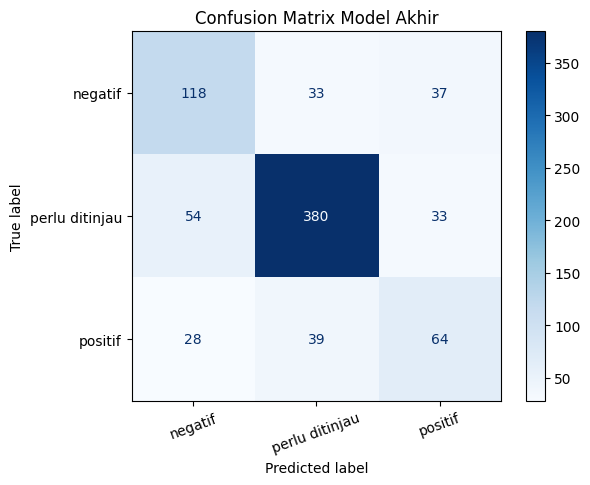

In [40]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", xticks_rotation=20)
plt.title("Confusion Matrix Model Akhir")
plt.show()

**Hasil:**

**Bayesian Search** (100 percobaan): pengaturan terbaik `C = 0,58` dan `class_weight = "balanced"`.

| Pengaturan | Macro-F1 CV (data latih) | Macro-F1 uji | Akurasi uji |
|---|---|---|---|
| Awal (Bab 8, `C=1`) | 0,646 | 0,639 | 0,715 |
| **Bayesian Search (`C=0,58`)** | **0,648** | **0,640** | **0,716** |

**Metrik model akhir di data uji:**

| Metrik | Nilai |
|---|---|
| Akurasi | 0,716 |
| Macro precision | 0,637 |
| Macro recall | 0,644 |
| **Macro-F1** | **0,640** |
| Weighted-F1 | 0,718 |
| Cohen's kappa | 0,501 |

| Label | Precision | Recall | F1 |
|---|---|---|---|
| negatif | 0,590 | 0,628 | 0,608 |
| perlu ditinjau | 0,841 | 0,816 | 0,828 |
| positif | 0,481 | 0,489 | 0,485 |

**Confusion matrix** (baris = label asli, kolom = tebakan model):

| Asli \ Tebakan | negatif | perlu ditinjau | positif |
|---|---|---|---|
| **negatif** | **118** | 33 | 37 |
| **perlu ditinjau** | 54 | **381** | 32 |
| **positif** | 28 | 39 | **64** |

- Bayesian Search hanya menaikkan skor sedikit (CV 0,646 → 0,648), karena pengaturan awal sudah dekat dengan yang terbaik. Pengaturan yang paling berpengaruh adalah `class_weight="balanced"`.
- **Kappa 0,501** berarti kesepakatan model dengan label **sedang**, setara dengan kecocokan label Claude dengan manusia di Bab 5.3 (kappa 0,506). Artinya model sudah mendekati batas kualitas labelnya.
- Kesalahan terbanyak: 54 komentar "perlu ditinjau" ditebak negatif, serta negatif dan positif yang saling tertukar (37 dan 28 komentar), biasanya pada komentar sindiran atau yang nadanya campur.

Catatan: angka pada tabel di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit (sekitar 0,01).

**Bukti: menghitung metrik sendiri dari confusion matrix.** Tabel metrik di awal 9.2 menjelaskan arti setiap metrik. Sel ini membuktikannya dengan menghitung ulang **langsung dari kotak-kotak confusion matrix**, lalu mencocokkannya dengan hasil scikit-learn:

| Metrik | Rumus | Diambil dari confusion matrix |
|---|---|---|
| **Precision** | benar ÷ semua yang ditebak label itu | kotak diagonal ÷ jumlah **satu kolom** |
| **Recall** | benar ÷ semua yang aslinya label itu | kotak diagonal ÷ jumlah **satu baris** |
| **F1** | 2 × precision × recall ÷ (precision + recall) | gabungan keduanya |
| **Macro-F1** | (F1 negatif + F1 perlu ditinjau + F1 positif) ÷ 3 | rata-rata F1, setiap label sama penting |
| **Akurasi** | semua tebakan benar ÷ semua komentar | jumlah diagonal ÷ jumlah semua kotak |

In [41]:
daftar_label = ["negatif", "perlu ditinjau", "positif"]
cm = confusion_matrix(y_test, y_pred, labels=daftar_label)

bukti = []
for k in range(3):
    # 1. Ambil angka dari confusion matrix
    benar = cm[k, k]           # kotak diagonal = ditebak benar
    ditebak = cm[:, k].sum()   # jumlah satu kolom = semua yang ditebak label ini
    asli = cm[k, :].sum()      # jumlah satu baris = semua yang aslinya label ini

    # 2. Hitung precision, recall, dan F1 sesuai rumus
    precision = benar / ditebak
    recall = benar / asli
    f1 = 2 * precision * recall / (precision + recall)

    bukti.append([daftar_label[k], benar, ditebak, asli, precision, recall, f1])

bukti = pd.DataFrame(bukti, columns=["Label", "Benar", "Ditebak", "Asli", "Precision", "Recall", "F1"])

# 3. Macro-F1 = rata-rata F1 ketiga label, akurasi = semua diagonal / semua komentar
macro_f1 = bukti["F1"].mean()
akurasi = np.trace(cm) / cm.sum()

print("Macro-F1 hitung sendiri:", round(macro_f1, 3), "| scikit-learn:", round(f1_score(y_test, y_pred, average="macro"), 3))
print("Akurasi  hitung sendiri:", round(akurasi, 3), "| scikit-learn:", round(accuracy_score(y_test, y_pred), 3))
bukti.round(3)

Macro-F1 hitung sendiri: 0.639 | scikit-learn: 0.639
Akurasi  hitung sendiri: 0.715 | scikit-learn: 0.715


,Label,Benar,Ditebak,Asli,Precision,Recall,F1
0,negatif,118,200,188,0.590,0.628,0.608
1,perlu ditinjau,380,452,467,0.841,0.814,0.827
2,positif,64,134,131,0.478,0.489,0.483


**Grafik: precision, recall, dan F1 per label.** Setiap garis adalah satu metrik. Garis merah putus-putus adalah **macro-F1** (rata-rata ketiga titik hijau F1), dan garis abu-abu titik-titik adalah **akurasi**.

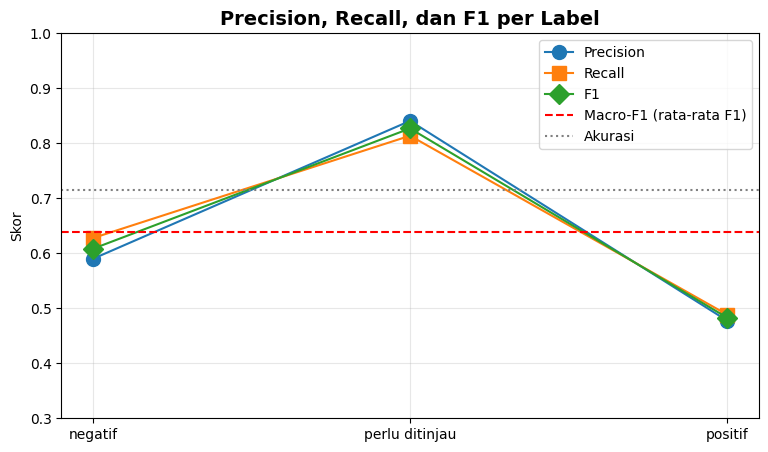

In [42]:
plt.figure(figsize=(9, 5))

# 1. Satu garis untuk setiap metrik
plt.plot(bukti["Label"], bukti["Precision"], "o-", markersize=10, label="Precision")
plt.plot(bukti["Label"], bukti["Recall"], "s-", markersize=10, label="Recall")
plt.plot(bukti["Label"], bukti["F1"], "D-", markersize=10, label="F1")

# 2. Macro-F1 (rata-rata F1) dan akurasi
plt.axhline(macro_f1, color="red", linestyle="--", label="Macro-F1 (rata-rata F1)")
plt.axhline(akurasi, color="gray", linestyle=":", label="Akurasi")

plt.ylim(0.3, 1)
plt.ylabel("Skor")
plt.title("Precision, Recall, dan F1 per Label", fontsize=14, fontweight="bold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Hasil:**

| Label | Benar (diagonal) | Ditebak (kolom) | Asli (baris) | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| negatif | 118 | 200 | 188 | 118 ÷ 200 = **0,590** | 118 ÷ 188 = **0,628** | **0,608** |
| perlu ditinjau | 381 | 453 | 467 | 381 ÷ 453 = **0,841** | 381 ÷ 467 = **0,816** | **0,828** |
| positif | 64 | 133 | 131 | 64 ÷ 133 = **0,481** | 64 ÷ 131 = **0,489** | **0,485** |

- **Macro-F1** = (0,608 + 0,828 + 0,485) ÷ 3 = **0,640**, dan **akurasi** = (118 + 381 + 64) ÷ 786 = 563 ÷ 786 = **0,716**. Keduanya **sama persis** dengan hasil scikit-learn, jadi rumus di tabel metrik terbukti.
- **Kenapa akurasi (0,716) lebih tinggi daripada macro-F1 (0,640)?** Akurasi dihitung per komentar, sehingga didominasi label terbanyak, yaitu "perlu ditinjau" (467 dari 786 komentar, F1 0,828). Macro-F1 menganggap ketiga label sama penting, sehingga label positif yang sulit (F1 0,485) ikut menurunkan skornya. Inilah alasan **macro-F1 dipakai sebagai metrik utama**.
- Pada grafik, ketiga garis hampir menempel di setiap label, artinya precision dan recall **seimbang**: model tidak terlalu sering menebak suatu label (precision rendah) dan tidak terlalu jarang (recall rendah). Ini hasil dari `class_weight="balanced"`.

**Grafik: kenyataan vs tebakan.** Label diubah menjadi angka (negatif = 0, perlu ditinjau = 1, positif = 2) supaya bisa digambar sebagai garis. Supaya tidak berantakan, yang digambar hanya **30 komentar uji pertama**, dan garis tebakan digeser sedikit ke atas supaya tidak menumpuk dengan garis kenyataan. Komentar yang **salah ditebak** diberi latar merah muda.

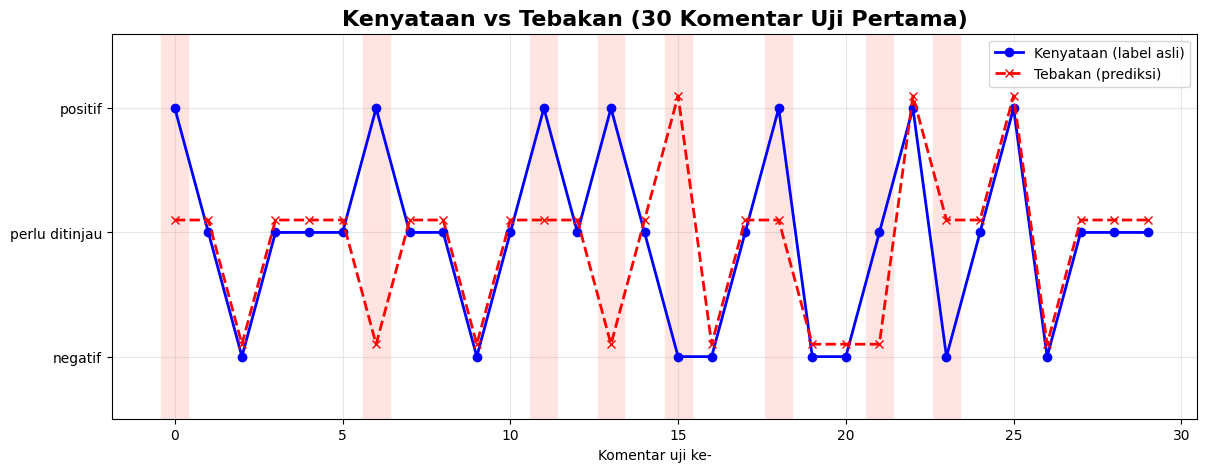

Tebakan benar di 30 komentar ini: 22


In [43]:
# 1. Ubah label menjadi angka supaya bisa digambar
angka_label = {"negatif": 0, "perlu ditinjau": 1, "positif": 2}
kenyataan = pd.Series(y_test[:30]).map(angka_label).to_numpy()
tebakan = pd.Series(y_pred[:30]).map(angka_label).to_numpy()

plt.figure(figsize=(14, 5))

# 2. Beri latar merah muda pada komentar yang salah ditebak
for i in range(30):
    if kenyataan[i] != tebakan[i]:
        plt.axvspan(i - 0.4, i + 0.4, color="mistyrose")

# 3. Garis kenyataan (biru) dan tebakan (merah putus-putus, digeser 0,1 ke atas supaya tidak menumpuk)
plt.plot(kenyataan, label="Kenyataan (label asli)", color="blue", marker="o", linewidth=2)
plt.plot(tebakan + 0.1, label="Tebakan (prediksi)", color="red", linestyle="dashed", marker="x", linewidth=2)

plt.yticks([0, 1, 2], ["negatif", "perlu ditinjau", "positif"])
plt.ylim(-0.5, 2.6)
plt.xlabel("Komentar uji ke-")
plt.title("Kenyataan vs Tebakan (30 Komentar Uji Pertama)", fontsize=16, fontweight="bold")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()

print("Tebakan benar di 30 komentar ini:", (kenyataan == tebakan).sum())

**Grafik: confusion matrix dalam persen.** Sama seperti confusion matrix di atas, tetapi setiap **baris dijadikan 100%**. Cara membacanya: *"dari semua komentar yang aslinya X, berapa persen yang ditebak Y?"*. Angka di diagonal adalah persentase yang ditebak benar (sama dengan *recall*).

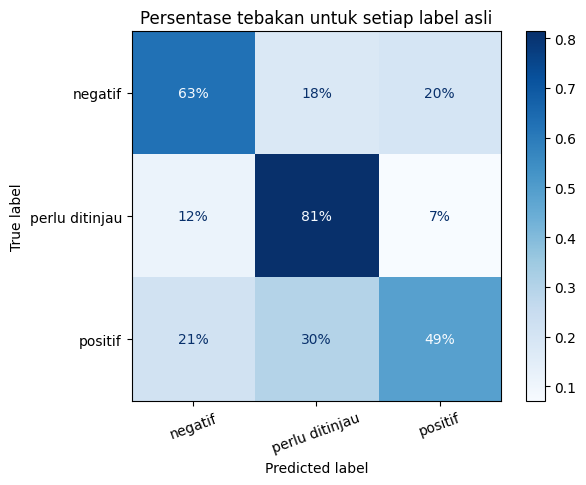

In [44]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", values_format=".0%",
                                        cmap="Blues", xticks_rotation=20)
plt.title("Persentase tebakan untuk setiap label asli")
plt.show()

**Grafik: kurva logistik dari skor SVM.** Gambar klasik Logistic Regression memperlihatkan titik-titik kelas 0 di bawah, kelas 1 di atas, dan kurva S (kurva logistik) yang mengubah nilai menjadi peluang 0 sampai 1. Model kami memakai **SVM** dengan 1.024 fitur dan 3 label, jadi gambarnya dibuat per label (**satu label vs bukan label itu**) dengan sumbu X berupa **skor SVM**:

- **Skor SVM** adalah jarak komentar dari garis pemisah. Makin besar skornya, makin yakin model bahwa komentar termasuk label tersebut. **Skor 0 adalah garis batas** (garis putus-putus).
- **Titik biru (bawah)** adalah komentar uji yang aslinya **bukan** label itu, dan **kotak hijau (atas)** adalah komentar yang aslinya **termasuk** label itu. Titik digeser acak sedikit ke atas/bawah supaya tidak menumpuk.
- **Kurva merah** mengubah skor SVM menjadi **peluang** (cara ini disebut *Platt scaling*). Kurvanya dilatih dari skor data latih, lalu digambar bersama titik-titik data uji.

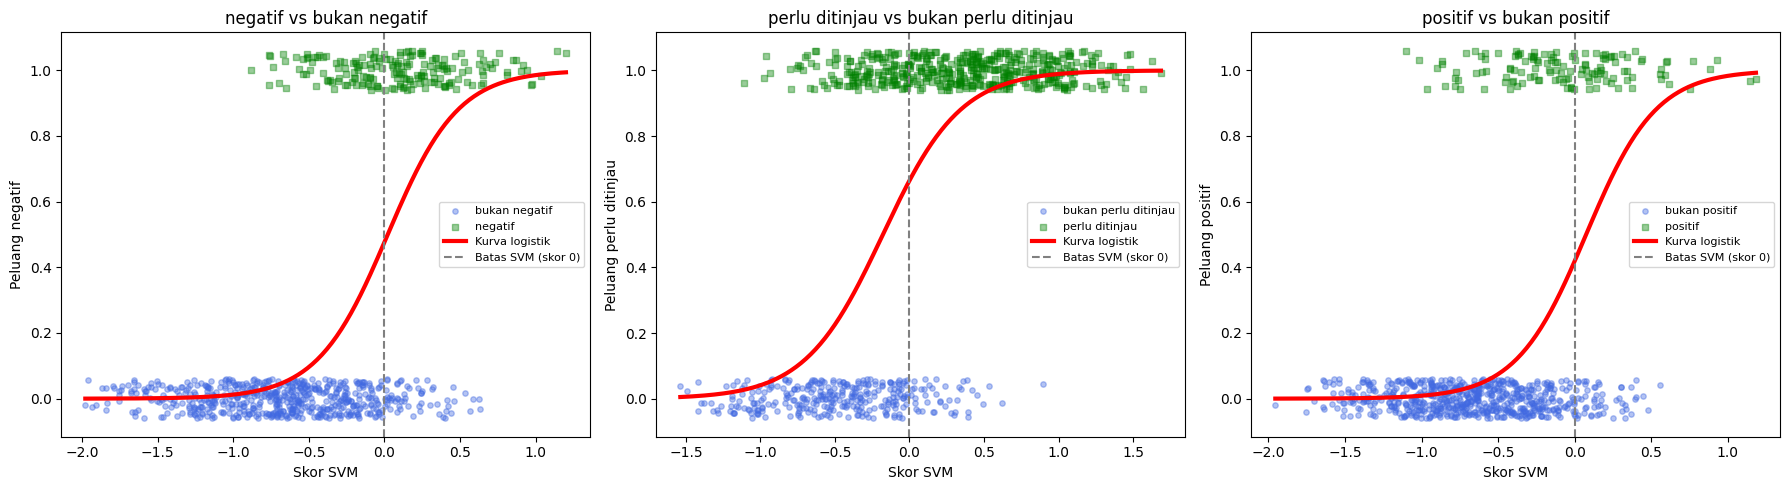

In [45]:
# Skor SVM: makin besar, makin yakin model bahwa komentar termasuk label itu (skor 0 = garis batas SVM)
skor_latih = best_model.decision_function(X_train)   # 3 kolom, urutannya sama dengan best_model.classes_
skor_uji = best_model.decision_function(X_test)
acak = np.random.default_rng(42)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for k, nama_label in enumerate(best_model.classes_):
    # 1. Label asli: 1 kalau komentar termasuk label ini, 0 kalau bukan
    asli_latih = (y_train == nama_label).astype(int)
    asli_uji = (y_test == nama_label).astype(int)

    # 2. Kurva logistik: mengubah skor SVM menjadi peluang (belajar dari data latih)
    kurva = LogisticRegression(random_state=42)
    kurva.fit(skor_latih[:, [k]], asli_latih)
    x_garis = np.linspace(skor_uji[:, k].min(), skor_uji[:, k].max(), 200)
    peluang = kurva.predict_proba(x_garis.reshape(-1, 1))[:, 1]

    # 3. Titik data uji, digeser acak sedikit ke atas/bawah supaya tidak menumpuk
    goyang = acak.uniform(-0.06, 0.06, len(asli_uji))
    bukan = asli_uji == 0
    ax[k].scatter(skor_uji[bukan, k], asli_uji[bukan] + goyang[bukan], marker="o", color="royalblue", s=15, alpha=0.4, label="bukan " + nama_label)
    ax[k].scatter(skor_uji[~bukan, k], asli_uji[~bukan] + goyang[~bukan], marker="s", color="green", s=15, alpha=0.4, label=nama_label)

    # 4. Kurva logistik dan garis batas SVM
    ax[k].plot(x_garis, peluang, color="red", linewidth=3, label="Kurva logistik")
    ax[k].axvline(0, color="gray", linestyle="--", label="Batas SVM (skor 0)")
    ax[k].set_title(nama_label + " vs bukan " + nama_label)
    ax[k].set_xlabel("Skor SVM")
    ax[k].set_ylabel("Peluang " + nama_label)
    ax[k].legend(loc="center right", fontsize=8)

plt.tight_layout()
plt.show()

**Hasil:**

| Label | Rata-rata skor komentar yang aslinya label itu | Rata-rata skor komentar yang bukan | Peluang di garis batas (skor 0) |
|---|---|---|---|
| negatif | 0,09 | -0,68 | 0,48 |
| perlu ditinjau | 0,36 | -0,48 | 0,66 |
| positif | -0,08 | -0,67 | 0,42 |

- Ketiga grafik membentuk **kurva S** seperti gambar Logistic Regression: makin besar skor SVM, makin besar peluang komentar termasuk label itu. Artinya **skor SVM memang bermakna**, dan SVM bisa dipakai untuk memberi tingkat keyakinan, bukan hanya tebakan.
- Pada ketiga label, kotak hijau (atas) cenderung berada di **kanan**, sedangkan titik biru (bawah) di **kiri**. Tetapi kedua kelompok masih **banyak tumpang-tindih di sekitar skor 0**, sehingga kurvanya naik secara landai, tidak tegak. Ini sesuai dengan macro-F1 sekitar 0,64: model cukup bisa membedakan, tetapi banyak komentar berada di daerah ragu-ragu.
- Untuk **negatif** dan **positif**, peluang di garis batas sekitar 0,4-0,5, jadi garis batas SVM hampir pas di titik peluang 50%. Untuk **perlu ditinjau**, peluang di garis batas sudah 0,66, karena label ini memang paling banyak (59,5%).

**Grafik: ilustrasi SVM (daerah 3 label dan support vector).** Model asli bekerja di **1.024 fitur**, jadi garis batasnya tidak bisa digambar langsung. Supaya bisa dilihat di bidang x-y, setiap komentar diringkas menjadi **2 angka**: skor negatif (sumbu x) dan skor positif (sumbu y) dari model terbaik. Kalau kedua skor rendah, berarti model condong ke **perlu ditinjau**. Lalu SVM linear kecil dilatih di 2 angka itu, hanya untuk ilustrasi, memakai 40 komentar acak per label dari data latih.

- **Warna latar** adalah daerah setiap label: komentar yang jatuh di daerah merah ditebak negatif, abu-abu ditebak perlu ditinjau, hijau ditebak positif.
- **Garis hitam** adalah garis batas antar-label. Karena ada 3 label, SVM membuat beberapa garis yang bertemu di tengah.
- **Titik yang dilingkari** adalah *support vector*: komentar di dekat garis batas (atau di sisi yang salah). Hanya titik-titik inilah yang menentukan letak garis batas.

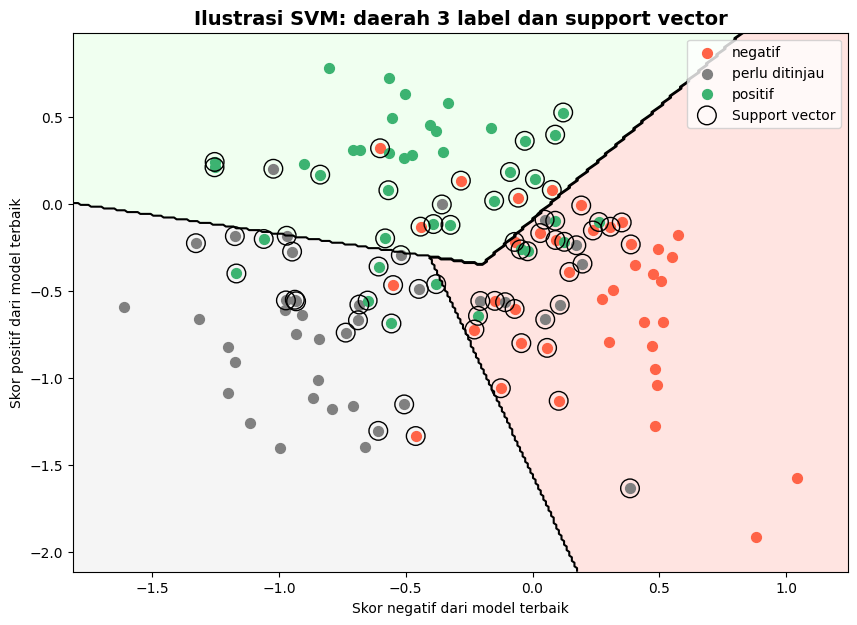

Jumlah support vector: 72 dari 120 komentar
Akurasi SVM 2 angka ini: 0.758


In [46]:
# 1. Ambil 40 komentar acak per label dari data latih
acak = np.random.default_rng(42)
idx = []
for nama_label in ["negatif", "perlu ditinjau", "positif"]:
    idx.extend(acak.choice(np.where(y_train == nama_label)[0], 40, replace=False))
y_tiga = y_train[idx]

# 2. Ringkas 1.024 fitur menjadi 2 angka: skor negatif dan skor positif dari model terbaik
#    (kalau keduanya rendah, berarti model condong ke "perlu ditinjau")
skor_model = best_model.decision_function(X_train[idx])
X_2d = skor_model[:, [0, 2]]   # kolom 0 = negatif, kolom 2 = positif (urutan best_model.classes_)

# 3. Latih SVM linear di 2 angka itu (hanya untuk ilustrasi)
svm_2d = SVC(kernel="linear", C=1)
svm_2d.fit(X_2d, y_tiga)

# 4. Tebak setiap titik bidang, untuk mewarnai daerah setiap label
x_grid, y_grid = np.meshgrid(
    np.linspace(X_2d[:, 0].min() - 0.2, X_2d[:, 0].max() + 0.2, 300),
    np.linspace(X_2d[:, 1].min() - 0.2, X_2d[:, 1].max() + 0.2, 300),
)
angka_label = {"negatif": 0, "perlu ditinjau": 1, "positif": 2}
tebakan_grid = svm_2d.predict(np.column_stack([x_grid.ravel(), y_grid.ravel()]))
daerah = pd.Series(tebakan_grid).map(angka_label).to_numpy().reshape(x_grid.shape)

plt.figure(figsize=(10, 7))

# 5. Daerah setiap label (warna muda) dan garis batasnya (hitam)
plt.contourf(x_grid, y_grid, daerah, levels=[-0.5, 0.5, 1.5, 2.5], colors=["mistyrose", "whitesmoke", "honeydew"])
plt.contour(x_grid, y_grid, daerah, levels=[0.5, 1.5], colors="black")

# 6. Titik komentar per label
warna_label = {"negatif": "tomato", "perlu ditinjau": "gray", "positif": "mediumseagreen"}
for nama_label in warna_label:
    pilih = y_tiga == nama_label
    plt.scatter(X_2d[pilih, 0], X_2d[pilih, 1], color=warna_label[nama_label], s=50, label=nama_label)

# 7. Lingkari support vector: titik di dekat garis batas yang menentukan letak garis
sv = svm_2d.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=180, facecolors="none", edgecolors="black", label="Support vector")

plt.xlabel("Skor negatif dari model terbaik")
plt.ylabel("Skor positif dari model terbaik")
plt.title("Ilustrasi SVM: daerah 3 label dan support vector", fontsize=14, fontweight="bold")
plt.legend(loc="upper right")
plt.show()

print("Jumlah support vector:", len(sv), "dari", len(X_2d), "komentar")
print("Akurasi SVM 2 angka ini:", round(svm_2d.score(X_2d, y_tiga), 3))

**Hasil:**

- Ketiga label menempati daerahnya masing-masing: **negatif** di kanan bawah (skor negatif tinggi), **positif** di kiri atas (skor positif tinggi), dan **perlu ditinjau** di kiri bawah (kedua skor rendah). Akurasi SVM kecil ini 82,5% pada 120 komentar tersebut.
- Ada **70 support vector dari 120 komentar**, kebanyakan di sekitar titik pertemuan ketiga garis. Ini komentar yang sikapnya samar, dan memang di sinilah model paling sering salah.
- Komentar positif paling sering bercampur dengan perlu ditinjau dan negatif di dekat garis batas. Ini sama dengan confusion matrix di atas: **positif adalah label yang paling sulit** (recall 49%).
- Komentar yang jauh dari garis (misalnya pojok kanan bawah atau kiri bawah) ditebak dengan sangat yakin, dan tidak ikut menentukan letak garis batas.

**Sel ini:** membandingkan jumlah setiap label menurut kenyataan dan menurut tebakan model, di seluruh 786 komentar uji.

In [47]:
pd.DataFrame({
    "Kenyataan": pd.Series(y_test).value_counts(),
    "Tebakan": pd.Series(y_pred).value_counts(),
})

,Kenyataan,Tebakan
perlu ditinjau,467,452
negatif,188,200
positif,131,134


**Hasil:**

- Pada grafik garis, dari 30 komentar uji pertama **22 ditebak benar**. Latar merah muda paling sering muncul saat salah satu garisnya berada di "perlu ditinjau": kesalahan terbanyak adalah tertukarnya "perlu ditinjau" dengan negatif/positif, jarang sampai negatif tertukar dengan positif.
- Confusion matrix persen menunjukkan:

| Label asli | Ditebak negatif | Ditebak perlu ditinjau | Ditebak positif |
|---|---|---|---|
| negatif | **63%** | 18% | 20% |
| perlu ditinjau | 12% | **82%** | 7% |
| positif | 21% | 30% | **49%** |

  "Perlu ditinjau" paling sering benar (82%), sedangkan **positif paling sulit**: hanya 49% yang ditebak benar, dan 30% dikira "perlu ditinjau" karena sikap positif sering disampaikan dengan nada santai atau tersirat.
- Jumlah tebakan setiap label **hampir sama dengan kenyataannya** (perlu ditinjau 453 vs 467, negatif 200 vs 188, positif 133 vs 131), jadi model **tidak berat sebelah** ke satu label, berkat `class_weight="balanced"`.

## **9.3 Cek Overfitting dan Underfitting**

| Kondisi | Tanda | Artinya |
|---|---|---|
| **Underfitting** | skor data latih **dan** data uji sama-sama rendah | model terlalu sederhana, belum menangkap pola |
| **Overfitting** | skor data latih jauh lebih tinggi daripada data uji, dan skor uji turun kalau model dibuat lebih rumit | model menghafal data latih, termasuk *noise*-nya |
| **Good fit** | selisih skor latih dan uji kecil, dan skor validasi paling tinggi | keseimbangan yang paling baik |

Tiga cara cek yang dipakai:
1. **Skor data latih vs data uji** dengan pengaturan terbaik.
2. **Kurva validasi `C`**: `C` diubah dari kecil (model sederhana) sampai besar (model rumit). Skor validasi diambil dari 5-fold CV di data latih, jadi data uji tidak dipakai.
3. **Kurva belajar (*learning curve*)**: model dilatih dengan 20%, 40%, ..., 100% data latih, untuk melihat apakah menambah data masih menaikkan skor.

**Sel ini:** membandingkan skor data latih dan data uji, keseluruhan dan per label.

In [48]:
# Model menebak data latihnya sendiri
y_pred_train = best_model.predict(X_train)

print("Akurasi  - latih:", round(accuracy_score(y_train, y_pred_train), 3), "| uji:", round(accuracy_score(y_test, y_pred), 3))
print("Macro-F1 - latih:", round(f1_score(y_train, y_pred_train, average="macro"), 3), "| uji:", round(f1_score(y_test, y_pred, average="macro"), 3))

Akurasi  - latih: 0.794 | uji: 0.715
Macro-F1 - latih: 0.747 | uji: 0.639


In [49]:
# F1 per label di data latih dan data uji
label = ["negatif", "perlu ditinjau", "positif"]

tabel_fit = pd.DataFrame({
    "F1 latih": f1_score(y_train, y_pred_train, average=None, labels=label),
    "F1 uji": f1_score(y_test, y_pred, average=None, labels=label),
}, index=label)

tabel_fit["Selisih"] = tabel_fit["F1 latih"] - tabel_fit["F1 uji"]
tabel_fit.round(3)

,F1 latih,F1 uji,Selisih
negatif,0.717,0.608,0.109
perlu ditinjau,0.866,0.827,0.039
positif,0.656,0.483,0.173


**Sel ini:** membuat kurva validasi `C`. `class_weight` tetap memakai hasil Bayesian Search.

**Cara membaca grafik:** sumbu x adalah nilai `C` (skala log: kiri = model lebih sederhana, kanan = model lebih rumit). Ada dua garis, yaitu skor di **data latih** dan skor **validasi (5-fold CV)**.
- Kalau **kedua garis rendah**, model underfitting.
- Kalau **garis latih terus naik tetapi garis validasi turun**, model overfitting.
- `C` terbaik (garis putus-putus abu-abu) seharusnya berada di **puncak garis validasi**.

In [50]:
daftar_C = [0.001, 0.01, 0.1, round(study.best_params["C"], 3), 1, 10]
f1_latih_C = []
f1_cv_C = []

for C in daftar_C:
    # 1. Buat dan latih model dengan nilai C ini
    model = LinearSVC(C=C, class_weight=study.best_params["class_weight"], max_iter=10000, random_state=42)
    model.fit(X_train, y_train)

    # 2. Skor di data latih dan skor validasi (5-fold CV)
    f1_latih_C.append(f1_score(y_train, model.predict(X_train), average="macro"))
    f1_cv_C.append(cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro").mean())

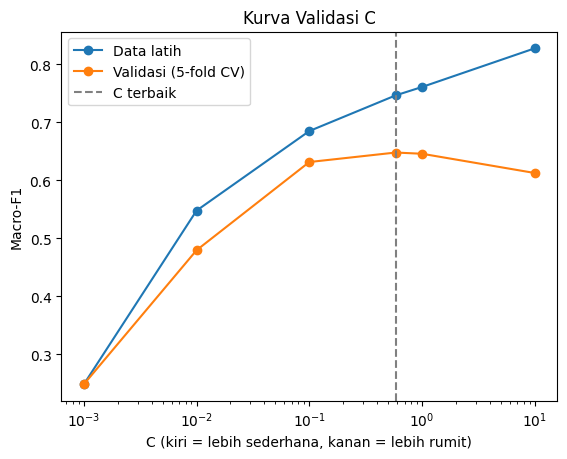

In [51]:
plt.plot(daftar_C, f1_latih_C, "o-", label="Data latih")
plt.plot(daftar_C, f1_cv_C, "o-", label="Validasi (5-fold CV)")
plt.axvline(study.best_params["C"], color="gray", linestyle="--", label="C terbaik")
plt.xscale("log")
plt.xlabel("C (kiri = lebih sederhana, kanan = lebih rumit)")
plt.ylabel("Macro-F1")
plt.title("Kurva Validasi C")
plt.legend()
plt.show()

In [52]:
pd.DataFrame({
    "C": daftar_C,
    "Macro-F1 latih": f1_latih_C,
    "Macro-F1 validasi (CV)": f1_cv_C,
}).round(3)

,C,Macro-F1 latih,Macro-F1 validasi (CV)
0,0.001,0.249,0.249
1,0.010,0.548,0.480
2,0.100,0.685,0.632
3,0.584,0.747,0.648
4,1.000,0.761,0.646
5,10.000,0.828,0.613


**Sel ini:** membuat kurva belajar. Sebagian data latih diambil secara *stratified* (`random_state=42`), model dilatih dengan pengaturan terbaik, lalu dinilai di data latihnya sendiri dan di data uji. Data uji di sini **hanya untuk melihat**, tidak dipakai memilih pengaturan.

**Cara membaca grafik:** sumbu x adalah jumlah komentar latih. Kalau jarak antara garis latih dan garis uji **makin rapat**, model makin umum (tidak menghafal). Kalau garis uji **masih naik** di ujung kanan, menambah data masih membantu. Kalau sudah **mendatar**, menambah data dengan kualitas yang sama tidak banyak membantu lagi.

In [53]:
porsi_data = [0.2, 0.4, 0.6, 0.8, 1.0]
jumlah_latih = []
f1_latih_belajar = []
f1_uji_belajar = []

for porsi in porsi_data:
    # 1. Ambil sebagian data latih (stratified)
    if porsi < 1:
        X_sebagian, _, y_sebagian, _ = train_test_split(X_train, y_train, train_size=porsi, random_state=42, stratify=y_train)
    else:
        X_sebagian, y_sebagian = X_train, y_train

    # 2. Latih model dengan pengaturan terbaik
    model = LinearSVC(C=study.best_params["C"], class_weight=study.best_params["class_weight"], max_iter=10000, random_state=42)
    model.fit(X_sebagian, y_sebagian)

    # 3. Skor di data latih sebagian itu dan di data uji
    jumlah_latih.append(len(X_sebagian))
    f1_latih_belajar.append(f1_score(y_sebagian, model.predict(X_sebagian), average="macro"))
    f1_uji_belajar.append(f1_score(y_test, model.predict(X_test), average="macro"))

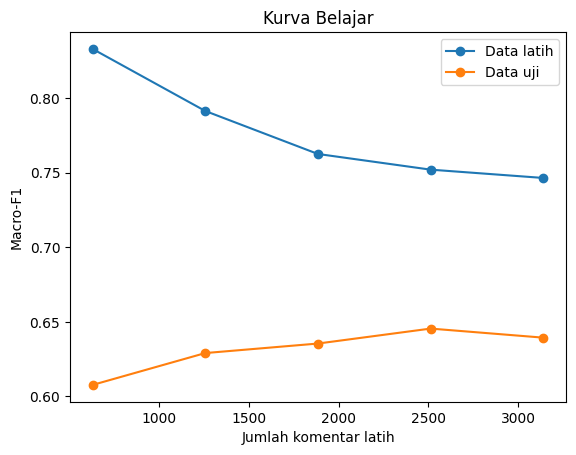

In [54]:
plt.plot(jumlah_latih, f1_latih_belajar, "o-", label="Data latih")
plt.plot(jumlah_latih, f1_uji_belajar, "o-", label="Data uji")
plt.xlabel("Jumlah komentar latih")
plt.ylabel("Macro-F1")
plt.title("Kurva Belajar")
plt.legend()
plt.show()

In [55]:
pd.DataFrame({
    "Porsi data latih": porsi_data,
    "Jumlah komentar": jumlah_latih,
    "Macro-F1 latih": f1_latih_belajar,
    "Macro-F1 uji": f1_uji_belajar,
}).round(3)

,Porsi data latih,Jumlah komentar,Macro-F1 latih,Macro-F1 uji
0,0.2,628,0.833,0.608
1,0.4,1256,0.791,0.629
2,0.6,1884,0.763,0.635
3,0.8,2512,0.752,0.646
4,1.0,3141,0.747,0.639


**Hasil:**

**1. Data latih vs data uji**

| | Data latih | Data uji | Selisih |
|---|---|---|---|
| Akurasi | 0,794 | 0,716 | 0,077 |
| Macro-F1 | 0,746 | 0,640 | 0,105 |
| F1 negatif | 0,716 | 0,608 | 0,108 |
| F1 perlu ditinjau | 0,866 | 0,828 | 0,038 |
| F1 positif | 0,655 | 0,485 | 0,170 |

**2. Kurva validasi `C`**

| C | Macro-F1 latih | Macro-F1 validasi (CV) | Kondisi |
|---|---|---|---|
| 0,001 | 0,249 | 0,249 | underfitting parah (hampir selalu menebak satu label) |
| 0,01 | 0,548 | 0,480 | underfitting |
| 0,1 | 0,685 | 0,632 | mendekati terbaik |
| **0,58 (terpilih)** | **0,746** | **0,648** | **titik terbaik** |
| 1 | 0,761 | 0,646 | hampir sama |
| 10 | 0,828 | 0,613 | overfitting (latih naik, validasi turun) |

**3. Kurva belajar**

| Jumlah komentar latih | Macro-F1 latih | Macro-F1 uji |
|---|---|---|
| 628 (20%) | 0,833 | 0,608 |
| 1.256 (40%) | 0,791 | 0,629 |
| 1.884 (60%) | 0,763 | 0,633 |
| 2.512 (80%) | 0,751 | 0,646 |
| 3.141 (100%) | 0,746 | 0,640 |

**Kesimpulan cek fit:**
- **Good fit.** Selisih latih-uji hanya **0,105** (akurasi 0,077). Skor latih tidak mendekati sempurna, jadi model tidak menghafal data latih.
- **Tidak underfitting.** Model yang lebih sederhana (`C` kecil) skornya turun tajam, sedangkan `C = 0,58` berada di puncak kurva validasi.
- **Pengaturan terpilih adalah titik terbaik.** Model yang lebih rumit (`C = 10`) mulai overfitting: skor latih naik tetapi skor validasi turun.
- **Kurva belajar:** garis latih turun dan garis uji naik seiring bertambahnya data, sehingga keduanya makin rapat. Skor uji naik dari 0,608 ke sekitar 0,64-0,65, lalu mulai mendatar. Menambah data masih sedikit membantu, tetapi kenaikan lebih besar butuh label yang lebih konsisten.
- Label **positif** punya selisih terbesar (0,170) karena contohnya paling sedikit.

Catatan: angka pada tabel di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit (sekitar 0,01).

## **9.4 Cek Robustness**

Model disebut **robust** (tangguh) jika skornya **stabil**, tidak naik-turun jauh hanya karena data yang dipakai sedikit berbeda. Tiga cara cek:
1. **Skor per fold**: 5-fold CV di data latih. Jika simpangan bakunya (*std*) kecil, model stabil di berbagai potongan data.
2. **Bootstrap data uji**: 786 komentar uji diambil ulang secara acak dengan pengembalian sebanyak 1.000 kali (`random_state=42`), lalu macro-F1 dihitung setiap kali. Rentang 95% hasilnya menunjukkan seberapa jauh skor uji bisa bergeser karena kebetulan.
3. **Uji lintas video (*leave-one-video-out*)**: model dilatih dengan komentar dari 5 video, lalu diuji di 1 video yang **tidak pernah dilihat**, diulang untuk keenam video. Ini meniru otomasi sungguhan, yaitu melabeli komentar dari video baru.

**Sel ini:** menghitung skor per fold dan rentang bootstrap 95%.

In [56]:
# 1. Skor per fold (5-fold CV di data latih)
skor_fold = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="f1_macro")

print("Macro-F1 per fold:", skor_fold.round(3))
print("Rata-rata        :", round(skor_fold.mean(), 3))
print("Simpangan baku   :", round(skor_fold.std(), 3))

Macro-F1 per fold: [0.639 0.646 0.64  0.626 0.689]
Rata-rata        : 0.648
Simpangan baku   : 0.022


In [57]:
# 2. Bootstrap: ambil ulang data uji secara acak (dengan pengembalian) sebanyak 1.000 kali
acak = np.random.default_rng(42)
skor_bootstrap = []

for _ in range(1000):
    i = acak.integers(0, len(y_test), len(y_test))
    skor_bootstrap.append(f1_score(y_test[i], y_pred[i], average="macro"))

print("Macro-F1 uji          :", round(f1_score(y_test, y_pred, average="macro"), 3))
print("Rentang 95% bootstrap :", round(np.percentile(skor_bootstrap, 2.5), 3), "-", round(np.percentile(skor_bootstrap, 97.5), 3))

Macro-F1 uji          : 0.639
Rentang 95% bootstrap : 0.601 - 0.676


**Sel ini:** uji lintas video. Untuk setiap video, model dilatih dengan komentar dari 5 video lain lalu dinilai di video tersebut.

In [58]:
video = df["video_title"].to_numpy()
hasil_video = []

for judul in df["video_title"].unique():
    # 1. Pisahkan komentar video ini dari 5 video lainnya
    di_video = video == judul

    # 2. Latih dengan 5 video lain, lalu uji di video ini
    model = LinearSVC(C=study.best_params["C"], class_weight=study.best_params["class_weight"], max_iter=10000, random_state=42)
    model.fit(X[~di_video], y[~di_video])
    skor = f1_score(y[di_video], model.predict(X[di_video]), average="macro")

    hasil_video.append({"Video yang diuji": judul, "Jumlah komentar": di_video.sum(), "Macro-F1": skor})

hasil_video = pd.DataFrame(hasil_video)
hasil_video.round(3)

,Video yang diuji,Jumlah komentar,Macro-F1
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,689,0.583
1,Manusia Belum Tergantikan AI Karena Satu Hamba...,778,0.577
2,Humans Need Not Apply - CGP Grey,1259,0.536
3,The EXACT moment AI took my job...,215,0.593
4,UK unemployment soars: is AI already taking ou...,861,0.574
5,AI is taking their jobs. But they're fighting ...,125,0.675


In [59]:
print("Rata-rata lintas video:", round(hasil_video["Macro-F1"].mean(), 3))
print("Simpangan baku       :", round(np.std(hasil_video["Macro-F1"]), 3))

Rata-rata lintas video: 0.59
Simpangan baku       : 0.042


**Grafik: robustness dalam satu gambar.**
- **Kiri (bootstrap):** sebaran 1.000 macro-F1 hasil pengambilan ulang data uji. Garis putus-putus abu-abu adalah rentang 95%, garis merah adalah skor data uji, dan garis hijau titik-titik adalah rata-rata 5-fold CV. Kalau garis merah dan hijau sama-sama berada di tengah rentang, skor uji **bukan kebetulan**.
- **Kanan (lintas video):** setiap titik adalah macro-F1 pada satu video yang **tidak pernah dilihat** model. Garis putus-putus biru adalah rata-ratanya, dan garis merah adalah skor data uji biasa. Jarak antara keduanya menunjukkan **seberapa besar skor turun pada video baru**.

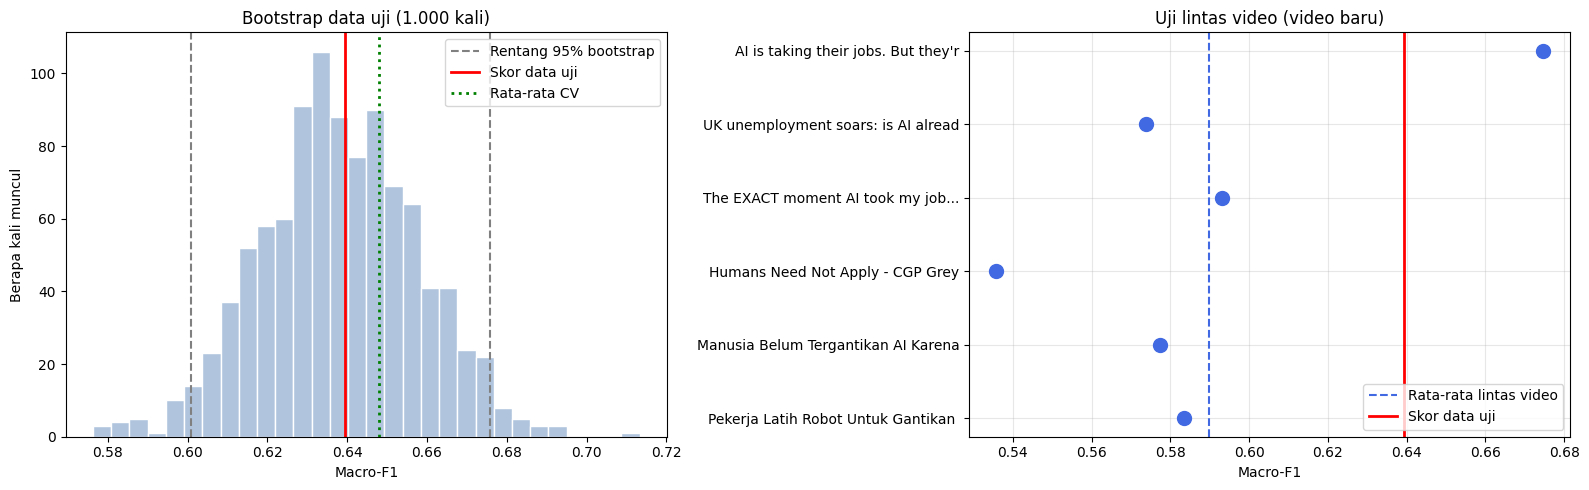

In [60]:
skor_uji = f1_score(y_test, y_pred, average="macro")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# 1. Kiri: sebaran 1.000 skor bootstrap, rentang 95%, skor uji, dan rata-rata CV
ax[0].hist(skor_bootstrap, bins=30, color="lightsteelblue", edgecolor="white")
ax[0].axvline(np.percentile(skor_bootstrap, 2.5), color="gray", linestyle="--", label="Rentang 95% bootstrap")
ax[0].axvline(np.percentile(skor_bootstrap, 97.5), color="gray", linestyle="--")
ax[0].axvline(skor_uji, color="red", linewidth=2, label="Skor data uji")
ax[0].axvline(skor_fold.mean(), color="green", linewidth=2, linestyle=":", label="Rata-rata CV")
ax[0].set_xlabel("Macro-F1")
ax[0].set_ylabel("Berapa kali muncul")
ax[0].set_title("Bootstrap data uji (1.000 kali)")
ax[0].legend()

# 2. Kanan: skor setiap video yang tidak pernah dilihat model
ax[1].plot(hasil_video["Macro-F1"], range(len(hasil_video)), "o", color="royalblue", markersize=10)
ax[1].set_yticks(range(len(hasil_video)), hasil_video["Video yang diuji"].str[:35])
ax[1].axvline(hasil_video["Macro-F1"].mean(), color="royalblue", linestyle="--", label="Rata-rata lintas video")
ax[1].axvline(skor_uji, color="red", linewidth=2, label="Skor data uji")
ax[1].set_xlabel("Macro-F1")
ax[1].set_title("Uji lintas video (video baru)")
ax[1].legend(loc="lower right")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Hasil:**

| Cek | Hasil |
|---|---|
| Macro-F1 per fold (5-fold CV) | 0,639 / 0,646 / 0,640 / 0,626 / 0,688 |
| Rata-rata ± simpangan baku | **0,648 ± 0,021** |
| Macro-F1 data uji | 0,640 |
| Rentang 95% bootstrap data uji | **0,603 - 0,676** |

**Uji lintas video** (model tidak pernah melihat video yang diuji):

| Video yang diuji | Jumlah komentar | Macro-F1 |
|---|---|---|
| Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI! | 689 | 0,584 |
| Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | 778 | 0,577 |
| Humans Need Not Apply - CGP Grey | 1.259 | 0,536 |
| The EXACT moment AI took my job... | 215 | 0,593 |
| UK unemployment soars: is AI already taking our jobs? | 861 | 0,574 |
| AI is taking their jobs. But they're fighting back. | 125 | 0,675 |
| **Rata-rata ± simpangan baku** | | **0,590 ± 0,042** |

- **Stabil antar-fold dan konsisten.** Skor uji (0,640) hampir sama dengan skor CV (0,648) dan berada di dalam rentang bootstrap, jadi pengaturan tidak "kebetulan cocok" dengan data latih.
- **Pada video baru, skor turun ke sekitar 0,59.** Inilah gambaran **realistis untuk otomasi**: komentar dari video baru punya topik dan gaya bahasa yang berbeda. Penurunannya merata (0,54-0,68), tidak ada video yang membuat model gagal total.
- Video **CGP Grey** paling sulit (0,536), karena komentarnya banyak berupa candaan dan diskusi filosofis yang sikapnya tidak jelas.
- **Pada grafik bootstrap**, skor uji (0,640) dan rata-rata CV (0,648) sama-sama berada di tengah sebaran, jauh dari kedua batas rentang 95%. Artinya skor model **tidak bergantung pada keberuntungan** pemilihan data uji.
- **Pada grafik lintas video**, semua titik berada di kiri garis merah: setiap video baru skornya lebih rendah daripada data uji biasa. Titik paling kiri adalah CGP Grey (paling banyak candaan), dan titik paling kanan adalah "AI is taking their jobs" (sikapnya paling lugas).

Catatan: angka pada tabel di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit (sekitar 0,01).

## **9.5 Perbandingan dengan Model Lain**

Apakah model lain bisa lebih baik? Semua pembanding diuji dengan **data latih, data uji, fold CV, dan pembagian video yang sama**:

| Model | Fitur | Keterangan |
|---|---|---|
| **SVM linear** | **TF-IDF saja** (kolom `teks` hasil Bab 6, unigram + bigram, maks. 20.000 kolom) | **baseline klasik** yang sering dipakai pada penelitian sentimen bahasa Indonesia, tanpa embedding |
| **Multinomial Naive Bayes** | **hitungan kata** (kolom `teks` hasil Bab 6, unigram + bigram, maks. 20.000 kolom) | baseline klasik lain yang paling populer untuk teks |
| **Gaussian Naive Bayes** | e5-large | Naive Bayes dengan embedding: versi Naive Bayes yang bisa membaca angka desimal, termasuk angka negatif |
| Logistic Regression | e5-large | model linear lain |
| KNN (k=15) | e5-large | menebak dari 15 komentar paling mirip (jarak *cosine*) |
| Logistic Regression | e5-large + **TF-IDF** (kolom `teks` hasil Bab 6, unigram + bigram, maks. 20.000 kolom) | TF-IDF dilatih ulang di setiap fold, hanya dari data latih fold tersebut |
| XLM-RoBERTa-large | teks asli | *fine-tuning* Transformer di Google Colab (notebook `finetune_transformer_colab.ipynb`) |

Pengaturan pembanding adalah nilai dengan skor CV tertinggi pada percobaan terpisah di data latih (termasuk Bayesian Search untuk e5-large + TF-IDF + LR).

Setiap model dievaluasi di **sel sendiri**, lalu semuanya dibandingkan dalam satu tabel dan grafik.

**Sel ini:** membuat fungsi `evaluasi` yang menghitung skor CV, skor latih, skor uji, akurasi uji, dan skor lintas video untuk satu model, lalu menyimpannya ke `hasil_banding`.

In [61]:
# Nomor baris data latih dan data uji di tabel df (dipakai oleh model pembanding)
idx_train = df_train.index.to_numpy()
idx_test = df_test.index.to_numpy()
teks = df["teks"].to_numpy()

In [62]:
hasil_banding = []
skor_per_video = {}


def evaluasi(nama, tebak):
    """tebak(baris_latih, baris_tebak): latih model di baris_latih, lalu kembalikan tebakan untuk baris_tebak."""
    # 1. Skor 5-fold CV di data latih
    skor_cv = []
    for a, b in cv.split(X_train, y_train):
        tebakan = tebak(idx_train[a], idx_train[b])
        skor_cv.append(f1_score(y[idx_train[b]], tebakan, average="macro"))

    # 2. Skor di data latih dan data uji
    tebakan_latih = tebak(idx_train, idx_train)
    tebakan_uji = tebak(idx_train, idx_test)

    # 3. Skor lintas video (latih dengan 5 video, uji di 1 video)
    skor_video = {}
    for judul in df["video_title"].unique():
        di_video = video == judul
        tebakan_video = tebak(np.where(~di_video)[0], np.where(di_video)[0])
        skor_video[judul] = f1_score(y[di_video], tebakan_video, average="macro")
    skor_per_video[nama] = skor_video

    # 4. Simpan semua skor
    hasil = {
        "Model": nama,
        "Macro-F1 CV": np.mean(skor_cv),
        "Macro-F1 latih": f1_score(y[idx_train], tebakan_latih, average="macro"),
        "Macro-F1 uji": f1_score(y_test, tebakan_uji, average="macro"),
        "Akurasi uji": accuracy_score(y_test, tebakan_uji),
        "Lintas video": np.mean(list(skor_video.values())),
    }
    hasil_banding.append(hasil)
    return hasil

**Pembanding 1: TF-IDF + SVM linear (baseline klasik).** Cara klasik yang paling sering dipakai pada penelitian sentimen bahasa Indonesia: teks diubah menjadi angka dengan **TF-IDF saja** (tanpa e5-large), lalu diklasifikasi dengan SVM linear. Pembanding ini menjawab pertanyaan: **apakah embedding e5-large memang lebih baik daripada cara klasik?**

TF-IDF memakai kolom `teks` hasil Bab 6 (unigram + bigram, maksimal 20.000 kolom) dan dilatih ulang setiap kali hanya dari data latihnya. `C = 0,3` dipilih karena skor 5-fold CV-nya tertinggi di antara 0,03 / 0,1 / 0,3 / 1 / 3 pada percobaan terpisah di data latih.

In [63]:
def tebak_tfidf_svm(baris_latih, baris_tebak):
    # 1. TF-IDF hanya belajar kosakata dari baris latih
    tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=20000)
    fitur_latih = tfidf.fit_transform(teks[baris_latih])
    fitur_tebak = tfidf.transform(teks[baris_tebak])

    # 2. Latih SVM linear, lalu tebak
    model = LinearSVC(C=0.3, class_weight="balanced", max_iter=10000, random_state=42)
    model.fit(fitur_latih, y[baris_latih])
    return model.predict(fitur_tebak)


evaluasi("TF-IDF + SVM linear", tebak_tfidf_svm)

{'Model': 'TF-IDF + SVM linear',
 'Macro-F1 CV': np.float64(0.5664131912709591),
 'Macro-F1 latih': 0.9776733520182218,
 'Macro-F1 uji': 0.5685309821898752,
 'Akurasi uji': 0.6679389312977099,
 'Lintas video': np.float64(0.4691599972387304)}

**Pembanding 2: Multinomial Naive Bayes (baseline klasik).** Naive Bayes populer untuk teks karena cepat dan sederhana: model menghitung seberapa sering setiap kata muncul pada setiap label, lalu menebak label yang paling cocok dengan kata-kata dalam komentar. Dipakai **Multinomial Naive Bayes**, bentuk Naive Bayes yang paling umum untuk teks, dengan fitur **hitungan kata** (`CountVectorizer`), karena Multinomial Naive Bayes memang dirancang untuk menghitung berapa kali kata muncul.

Hitungan kata memakai kolom `teks` hasil Bab 6 (unigram + bigram, maksimal 20.000 kolom) dan dilatih ulang setiap kali hanya dari data latihnya. `alpha = 0,3` dipilih karena skor 5-fold CV-nya tertinggi di antara 0,1 / 0,3 / 1 pada percobaan terpisah di data latih. Multinomial Naive Bayes tidak bisa dipasangkan dengan e5-large, karena hanya bisa membaca angka hitungan (tidak boleh negatif), sedangkan angka embedding bisa negatif. Untuk e5-large dipakai Gaussian Naive Bayes (pembanding 3).

In [64]:
def tebak_nb(baris_latih, baris_tebak):
    # 1. Hitungan kata hanya belajar kosakata dari baris latih
    hitung_kata = CountVectorizer(ngram_range=(1, 2), max_features=20000)
    fitur_latih = hitung_kata.fit_transform(teks[baris_latih])
    fitur_tebak = hitung_kata.transform(teks[baris_tebak])

    # 2. Latih Multinomial Naive Bayes, lalu tebak
    model = MultinomialNB(alpha=0.3)
    model.fit(fitur_latih, y[baris_latih])
    return model.predict(fitur_tebak)


evaluasi("Naive Bayes", tebak_nb)

{'Model': 'Naive Bayes',
 'Macro-F1 CV': np.float64(0.5259634535460539),
 'Macro-F1 latih': 0.9414437093010024,
 'Macro-F1 uji': 0.5311558074375061,
 'Akurasi uji': 0.6183206106870229,
 'Lintas video': np.float64(0.34317015792793565)}

**Pembanding 3: e5-large + Gaussian Naive Bayes.** Supaya Naive Bayes juga diuji dengan embedding e5-large, dipakai **Gaussian Naive Bayes**: setiap fitur dianggap mengikuti kurva normal (lonceng) di setiap label, sehingga bisa membaca angka desimal, termasuk angka negatif. Pengaturannya bawaan (tidak ada parameter yang perlu dipilih).

Naive Bayes tetap menganggap setiap fitur **berdiri sendiri**, padahal 1.024 angka embedding saling berkaitan. Pembanding ini menunjukkan apakah kelemahan Naive Bayes ada pada fiturnya (hitungan kata) atau pada cara kerjanya.

In [65]:
def tebak_gnb(baris_latih, baris_tebak):
    model = GaussianNB()
    model.fit(X[baris_latih], y[baris_latih])
    return model.predict(X[baris_tebak])


evaluasi("e5-large + Naive Bayes", tebak_gnb)

{'Model': 'e5-large + Naive Bayes',
 'Macro-F1 CV': np.float64(0.5911829715540321),
 'Macro-F1 latih': 0.6274053109150683,
 'Macro-F1 uji': 0.596869784493384,
 'Akurasi uji': 0.6564885496183206,
 'Lintas video': np.float64(0.5131618907325702)}

**Pembanding 4: e5-large + Logistic Regression** (`C=3`, `class_weight="balanced"`).

In [66]:
def tebak_lr(baris_latih, baris_tebak):
    model = LogisticRegression(C=3, class_weight="balanced", max_iter=3000, random_state=42)
    model.fit(X[baris_latih], y[baris_latih])
    return model.predict(X[baris_tebak])


evaluasi("e5-large + LR", tebak_lr)

{'Model': 'e5-large + LR',
 'Macro-F1 CV': np.float64(0.6419794659127048),
 'Macro-F1 latih': 0.729471564381802,
 'Macro-F1 uji': 0.6333495200061917,
 'Akurasi uji': 0.6857506361323156,
 'Lintas video': np.float64(0.5875166319438504)}

**Pembanding 5: e5-large + KNN** (15 tetangga terdekat, jarak *cosine*).

In [67]:
def tebak_knn(baris_latih, baris_tebak):
    model = KNeighborsClassifier(n_neighbors=15, metric="cosine")
    model.fit(X[baris_latih], y[baris_latih])
    return model.predict(X[baris_tebak])


evaluasi("e5-large + KNN (k=15)", tebak_knn)

{'Model': 'e5-large + KNN (k=15)',
 'Macro-F1 CV': np.float64(0.6188909131417942),
 'Macro-F1 latih': 0.6962536419753528,
 'Macro-F1 uji': 0.656458300279941,
 'Akurasi uji': 0.7086513994910941,
 'Lintas video': np.float64(0.5043448866796275)}

**Grafik: ilustrasi cara kerja KNN.** KNN tidak membuat garis batas. Untuk menebak komentar baru (**Pt**, bintang kuning), KNN mencari **15 komentar latih yang paling mirip** (jarak *cosine* di 1.024 fitur e5-large), lalu label yang paling banyak di antara 15 tetangga itu menjadi tebakannya (**voting**).

Supaya bisa digambar, 1.024 fitur diringkas menjadi 2 angka dengan **t-SNE**, yaitu cara meringkas yang menjaga komentar yang mirip tetap berdekatan. Yang digambar hanya 40 komentar latih acak per label, ditambah 15 tetangga tadi. Panah menunjuk ke 15 tetangga terdekat.

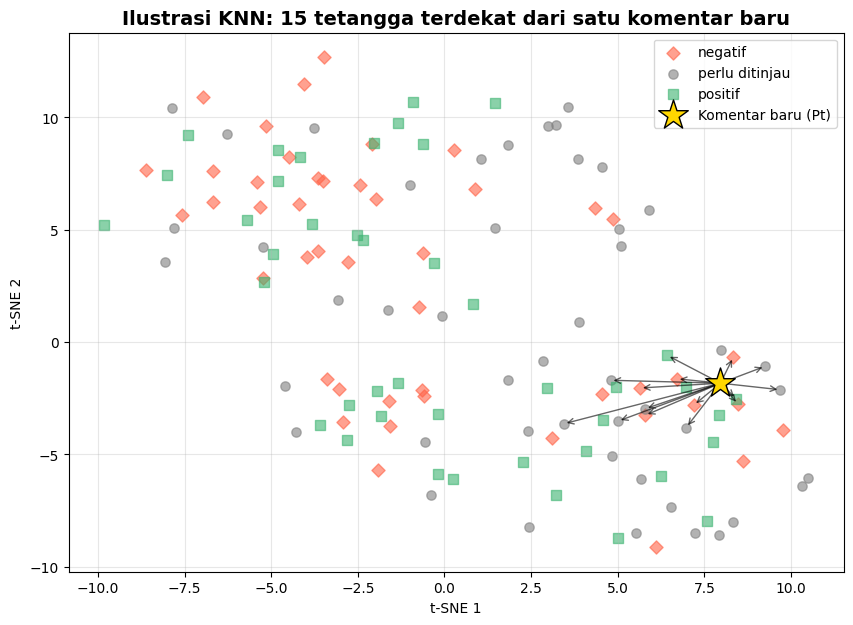

Komentar: Disini ada yang ngerasa kesel gak sama customer service berbasis AI kita mau nyampein keluhan bukan cuma info tapi jawabannya aneh jadi ngerasa ngomon
Label asli: positif
Suara 15 tetangga:
perlu ditinjau    7
negatif           6
positif           2
Name: count, dtype: int64
Tebakan KNN: perlu ditinjau


In [68]:
# 1. Pilih satu komentar uji sebagai titik baru (Pt)
nomor_uji = 0
x_baru = X_test[nomor_uji]

# 2. Cari 15 komentar latih yang paling mirip (jarak cosine), sama seperti KNN di 9.5
knn = KNeighborsClassifier(n_neighbors=15, metric="cosine")
knn.fit(X_train, y_train)
idx_tetangga = knn.kneighbors([x_baru], return_distance=False)[0]

# 3. Ambil 40 komentar latih acak per label sebagai latar, ditambah 15 tetangga tadi
acak = np.random.default_rng(42)
idx_latar = []
for nama_label in ["negatif", "perlu ditinjau", "positif"]:
    idx_latar.extend(acak.choice(np.where(y_train == nama_label)[0], 40, replace=False))
idx_gambar = np.unique(np.concatenate([idx_latar, idx_tetangga]))

# 4. Ringkas 1.024 fitur menjadi 2 angka dengan t-SNE (komentar yang mirip tetap berdekatan)
X_gambar = np.vstack([X_train[idx_gambar], [x_baru]])
X_2d = TSNE(n_components=2, metric="cosine", perplexity=20, random_state=42).fit_transform(X_gambar)
titik_latih = X_2d[:-1]    # semua titik kecuali yang terakhir
titik_baru = X_2d[-1]      # titik terakhir = komentar baru
posisi = {}                # nomor baris latih -> posisinya di gambar
for urutan, i in enumerate(idx_gambar):
    posisi[i] = titik_latih[urutan]

warna_label = {"negatif": "tomato", "perlu ditinjau": "gray", "positif": "mediumseagreen"}
bentuk_label = {"negatif": "D", "perlu ditinjau": "o", "positif": "s"}

plt.figure(figsize=(10, 7))

# 5. Titik latar per label
for nama_label in warna_label:
    pilih = y_train[idx_gambar] == nama_label
    plt.scatter(titik_latih[pilih, 0], titik_latih[pilih, 1], color=warna_label[nama_label],
                marker=bentuk_label[nama_label], s=45, alpha=0.6, label=nama_label)

# 6. Panah dari titik baru ke 15 tetangga terdekatnya
for i in idx_tetangga:
    plt.annotate("", xy=posisi[i], xytext=titik_baru, arrowprops=dict(arrowstyle="->", color="black", alpha=0.6))

# 7. Titik baru (Pt)
plt.scatter(titik_baru[0], titik_baru[1], color="gold", edgecolors="black", marker="*", s=500, zorder=3, label="Komentar baru (Pt)")

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Ilustrasi KNN: 15 tetangga terdekat dari satu komentar baru", fontsize=14, fontweight="bold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 8. Suara tetangga: label terbanyak menjadi tebakan KNN
print("Komentar:", df_test["comment"].iloc[nomor_uji][:150])
print("Label asli:", y_test[nomor_uji])
print("Suara 15 tetangga:")
print(pd.Series(y_train[idx_tetangga]).value_counts())
print("Tebakan KNN:", knn.predict([x_baru])[0])

**Hasil:**

- Komentar baru yang dipilih adalah komentar uji pertama: *"Not me, I won't have the cash to pay them. In fact, I might not have running water as I can't afford it."* (label asli: **negatif**).
- Suara 15 tetangga: **9 negatif**, 4 perlu ditinjau, 2 positif, jadi KNN menebak **negatif** (benar).
- Hampir semua panah pendek, karena tetangganya memang berkumpul di dekat Pt. Ada satu panah panjang ke kanan: peringkasan dari 1.024 menjadi 2 angka tidak bisa sempurna, jadi tetangga yang dekat di 1.024 fitur kadang terlihat jauh di gambar.
- Tidak seperti contoh di buku, ketiga label **tidak membentuk kelompok yang terpisah rapi**, tetapi bercampur. Inilah sebabnya KNN mudah tertipu: komentar dari video yang sama cenderung mirip satu sama lain, sehingga di video baru tetangganya kurang cocok (skor lintas video KNN hanya 0,506).

**Pembanding 6: e5-large + TF-IDF + Logistic Regression.** TF-IDF memakai kolom `teks` hasil Bab 6 (unigram + bigram, maksimal 20.000 kolom, bobot 0,54) dan **dilatih ulang setiap kali hanya dari data latihnya**.

In [69]:
def tebak_tfidf_lr(baris_latih, baris_tebak):
    # 1. TF-IDF hanya belajar kosakata dari baris latih
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=20000)
    tfidf.fit(teks[baris_latih])

    # 2. Gabungkan fitur e5-large + TF-IDF (bobot TF-IDF 0,54)
    fitur_latih = hstack([csr_matrix(X[baris_latih]), tfidf.transform(teks[baris_latih]) * 0.54]).tocsr()
    fitur_tebak = hstack([csr_matrix(X[baris_tebak]), tfidf.transform(teks[baris_tebak]) * 0.54]).tocsr()

    # 3. Latih Logistic Regression, lalu tebak
    model = LogisticRegression(C=3.05, class_weight="balanced", max_iter=3000, random_state=42)
    model.fit(fitur_latih, y[baris_latih])
    return model.predict(fitur_tebak)


evaluasi("e5-large + TF-IDF + LR", tebak_tfidf_lr)

{'Model': 'e5-large + TF-IDF + LR',
 'Macro-F1 CV': np.float64(0.6648867314682593),
 'Macro-F1 latih': 0.8992592675447463,
 'Macro-F1 uji': 0.6578042546769293,
 'Akurasi uji': 0.7175572519083969,
 'Lintas video': np.float64(0.5867551368601744)}

**Pembanding 7: XLM-RoBERTa-large.** Hasilnya diambil dari notebook Colab `finetune_transformer_colab.ipynb` (data uji yang sama). Notebook ini dipisah karena *fine-tuning* XLM-RoBERTa-large (sekitar 560 juta parameter) butuh GPU yang lebih kuat: pelatihan dan pengujiannya dijalankan di **Google Colab** (GPU NVIDIA T4, 16 GB), karena GPU laptop (RTX 4050, 6 GB) tidak cukup. Skor CV, latih, dan lintas video tidak dihitung karena setiap pelatihan butuh sekitar 25 menit di GPU.

In [70]:
# Angka dari notebook Colab finetune_transformer_colab.ipynb (data uji yang sama)
hasil_banding.append({"Model": "XLM-RoBERTa-large (Colab)", "Macro-F1 uji": 0.623, "Akurasi uji": 0.659})

**Model akhir: e5-large + SVM linear** (pengaturan Bayesian Search).

In [71]:
def tebak_svm(baris_latih, baris_tebak):
    model = LinearSVC(C=study.best_params["C"], class_weight=study.best_params["class_weight"], max_iter=10000, random_state=42)
    model.fit(X[baris_latih], y[baris_latih])
    return model.predict(X[baris_tebak])


evaluasi("e5-large + SVM linear (model akhir)", tebak_svm)

{'Model': 'e5-large + SVM linear (model akhir)',
 'Macro-F1 CV': np.float64(0.647994467828043),
 'Macro-F1 latih': 0.7465059806291663,
 'Macro-F1 uji': 0.6394173815980922,
 'Akurasi uji': 0.7150127226463104,
 'Lintas video': np.float64(0.5897236736957643)}

**Sel ini:** menggabungkan semua hasil ke satu tabel.

In [72]:
tabel_banding = pd.DataFrame(hasil_banding).set_index("Model")
tabel_banding["Selisih latih-uji"] = tabel_banding["Macro-F1 latih"] - tabel_banding["Macro-F1 uji"]
tabel_banding.round(3)

,Macro-F1 CV,Macro-F1 latih,Macro-F1 uji,Akurasi uji,Lintas video,Selisih latih-uji
Model,,,,,,
TF-IDF + SVM linear,0.566,0.978,0.569,0.668,0.469,0.409
Naive Bayes,0.526,0.941,0.531,0.618,0.343,0.410
e5-large + Naive Bayes,0.591,0.627,0.597,0.656,0.513,0.031
e5-large + LR,0.642,0.729,0.633,0.686,0.588,0.096
e5-large + KNN (k=15),0.619,0.696,0.656,0.709,0.504,0.040
e5-large + TF-IDF + LR,0.665,0.899,0.658,0.718,0.587,0.241
XLM-RoBERTa-large (Colab),NaN,NaN,0.623,0.659,NaN,NaN
e5-large + SVM linear (model akhir),0.648,0.747,0.639,0.715,0.590,0.107


**Visualisasi 1: Skor vs good fit.** Setiap titik adalah satu model. Sumbu X adalah selisih skor latih-uji (**kiri = lebih good fit**), sumbu Y adalah skor lintas video (**atas = lebih bagus di video baru**). Model terbaik untuk otomasi berada di **kiri atas**. Grafik batang tidak bisa menunjukkan *trade-off* dua ukuran sekaligus seperti ini.

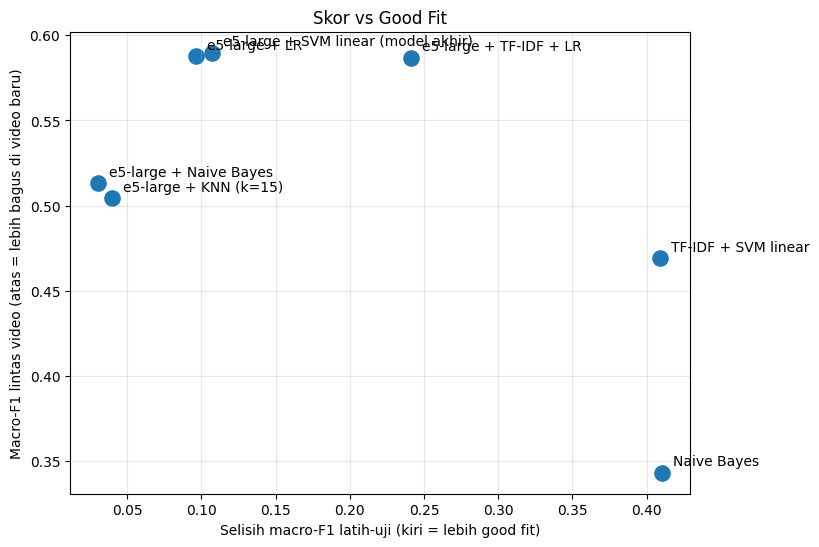

In [73]:
data_plot = tabel_banding.dropna()   # XLM-RoBERTa tidak punya skor lintas video, jadi tidak digambar

plt.figure(figsize=(8, 6))
plt.scatter(data_plot["Selisih latih-uji"], data_plot["Lintas video"], s=120)

# Tulis nama model di samping setiap titik
for nama in data_plot.index:
    x = data_plot.loc[nama, "Selisih latih-uji"]
    y_titik = data_plot.loc[nama, "Lintas video"]
    plt.annotate(nama, (x, y_titik), textcoords="offset points", xytext=(8, 5))

plt.xlabel("Selisih macro-F1 latih-uji (kiri = lebih good fit)")
plt.ylabel("Macro-F1 lintas video (atas = lebih bagus di video baru)")
plt.title("Skor vs Good Fit")
plt.grid(alpha=0.3)
plt.show()

**Visualisasi 2: Skor per video (*heatmap*).** Baris = model, kolom = video yang diuji (tidak pernah dilihat saat latihan). Warna gelap = skor tinggi. Dari sini terlihat **video mana yang sulit untuk semua model**, dan model mana yang paling stabil antar-video.

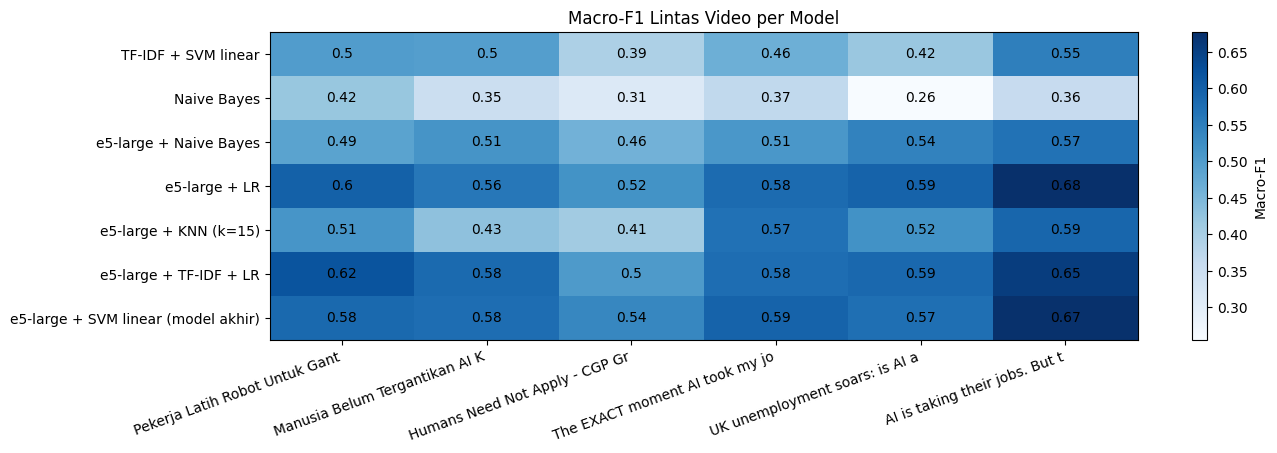

In [74]:
# Baris = model, kolom = video yang diuji
peta_video = pd.DataFrame(skor_per_video).T
peta_video.columns = [judul[:30] for judul in peta_video.columns]   # potong judul supaya muat

fig, ax = plt.subplots(figsize=(14, 4))
gambar = ax.imshow(peta_video.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(peta_video.columns)), peta_video.columns, rotation=20, ha="right")
ax.set_yticks(range(len(peta_video.index)), peta_video.index)

# Tulis angka di setiap kotak
for i in range(len(peta_video.index)):
    for j in range(len(peta_video.columns)):
        ax.text(j, i, round(peta_video.values[i, j], 2), ha="center", va="center")

plt.colorbar(gambar, label="Macro-F1")
plt.title("Macro-F1 Lintas Video per Model")
plt.show()

**Hasil:**

| Model | Macro-F1 CV | Macro-F1 latih | Macro-F1 uji | Akurasi uji | Lintas video | Selisih latih-uji |
|---|---|---|---|---|---|---|
| TF-IDF + SVM linear (baseline klasik) | 0,566 | 0,977 | 0,569 | 0,668 | 0,469 | **0,409** |
| Naive Bayes, hitungan kata (baseline klasik) | 0,525 | 0,942 | 0,531 | 0,618 | 0,343 | **0,411** |
| e5-large + Naive Bayes | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* |
| e5-large + LR | 0,641 | 0,729 | 0,642 | 0,692 | 0,585 | 0,087 |
| e5-large + KNN (k=15) | 0,619 | 0,695 | 0,659 | 0,710 | 0,506 | 0,037 |
| e5-large + TF-IDF + LR | **0,664** | 0,903 | **0,661** | **0,720** | 0,587 | 0,242 |
| XLM-RoBERTa-large (Colab) | - | - | 0,623 | 0,659 | - | - |
| **e5-large + SVM linear (model akhir)** | 0,648 | 0,746 | 0,640 | 0,716 | **0,590** | 0,105 |

**Skor per video (*heatmap*):**

| Model | Pekerja Latih Robot | Manusia Belum Tergantikan | CGP Grey | The EXACT moment | UK unemployment | AI is taking their jobs |
|---|---|---|---|---|---|---|
| TF-IDF + SVM linear | 0,497 | 0,498 | 0,392 | 0,464 | 0,417 | 0,548 |
| Naive Bayes (hitungan kata) | 0,419 | 0,348 | 0,312 | 0,367 | 0,255 | 0,359 |
| e5-large + Naive Bayes | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* |
| e5-large + LR | 0,594 | 0,560 | 0,514 | 0,577 | 0,599 | 0,667 |
| e5-large + KNN | 0,516 | 0,426 | **0,407** | 0,571 | 0,520 | 0,597 |
| e5-large + TF-IDF + LR | **0,618** | **0,585** | 0,503 | 0,582 | 0,586 | 0,649 |
| **e5-large + SVM linear** | 0,584 | 0,577 | **0,536** | **0,593** | 0,574 | **0,675** |

**Pola yang terlihat dari visualisasi:**
1. **Embedding e5-large jauh lebih baik daripada cara klasik TF-IDF.** Dua baseline klasik berada paling bawah dan paling overfitting: **TF-IDF + SVM linear** (uji 0,569, lintas video 0,469, selisih 0,409) dan **Naive Bayes dengan hitungan kata** (uji 0,531, lintas video 0,343 yang paling rendah dari semua model, selisih 0,411). Skor latih keduanya sangat tinggi (0,942-0,977), artinya baseline klasik hanya menghafal kata, sehingga gagal pada komentar dengan kata berbeda tetapi maksud sama, dan pada sindiran yang tidak memakai kata-kata khas sikap. Naive Bayes paling lemah karena menganggap setiap kata berdiri sendiri. Di grafik *scatter*, keduanya berada paling kanan bawah. Hasil **e5-large + Naive Bayes** menunjukkan apakah Naive Bayes membaik bila diberi embedding.
2. **Scatter skor vs good fit:** SVM linear berada paling dekat ke **kiri atas**, yaitu skor lintas video tertinggi (0,590) dengan selisih latih-uji kecil (0,105). TF-IDF + LR skornya setara di video baru (0,587) tetapi berada jauh di kanan (selisih 0,242), karena banyak menghafal kata-kata khas dari video yang sudah dilihat.
3. **KNN tampak bagus di data uji (0,659), tetapi gagal di video baru (0,506).** Pada video bahasa Indonesia "Manusia Belum Tergantikan" dan video CGP Grey, skornya hanya 0,41-0,43. KNN menebak dari komentar yang paling mirip. Di data uji biasa, komentar yang mirip berasal dari video yang sama sehingga tebakannya tepat, tetapi di video baru tetangganya berasal dari video lain dengan konteks berbeda. **Pola ini tidak terlihat dari skor uji biasa.**
4. **Video CGP Grey paling sulit untuk hampir semua model** (0,31-0,54), dan video "AI is taking their jobs" paling mudah untuk model berbasis e5-large (0,60-0,68).
5. **Keunggulan TF-IDF hanya muncul di data dari video yang sama.** Skor CV-nya tertinggi (0,664), tetapi di video baru sama dengan model tanpa TF-IDF (0,587 vs 0,585-0,590).
6. **XLM-RoBERTa-large** (sekitar 560 juta parameter) justru lebih rendah di data uji (0,623): mulai overfitting setelah epoch 3 dan terlalu sering menebak positif.

⚠️ **Angka bertanda *(lihat output)* belum diisi.** Pembanding **e5-large + Naive Bayes** baru ditambahkan, sehingga angkanya diambil dari output sel setelah notebook dijalankan di Google Colab.

**Kesimpulan:** embedding e5-large jelas lebih baik daripada fitur kata saja (baik dengan SVM maupun Naive Bayes), dan di antara model berbasis e5-large, SVM linear dipilih karena **paling seimbang untuk otomasi**: skor lintas video tertinggi, good fit, stabil, dan paling sederhana (hanya 1.024 fitur e5-large, tanpa TF-IDF). Model dengan skor CV tertinggi (TF-IDF + LR) tidak lebih baik untuk video baru dan lebih overfitting.

Catatan: angka pada tabel di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit (sekitar 0,01).

## **9.6 Uji Statistik (McNemar)**

Selisih skor antar-model di 9.5 kecil, jadi perlu dicek: **apakah perbedaannya nyata, atau hanya kebetulan?**

**Uji McNemar** adalah uji standar untuk membandingkan dua model klasifikasi pada **data yang sama**. Untuk setiap komentar dicek siapa yang benar:

| | Model lawan benar | Model lawan salah |
|---|---|---|
| **SVM benar** | (tidak dihitung) | **SVM unggul** |
| **SVM salah** | **lawan unggul** | (tidak dihitung) |

Jika jumlah "SVM unggul" dan "lawan unggul" kira-kira seimbang, kedua model **setara**. Jika timpang, salah satu model memang lebih baik. Hasilnya berupa **p-value**:
- **p < 0,05** → perbedaannya **signifikan** (bukan kebetulan);
- **p ≥ 0,05** → **tidak berbeda signifikan** (setara).

Uji dilakukan di dua tempat: **data uji** (786 komentar) dan **lintas video** (3.927 komentar, setiap komentar ditebak oleh model yang tidak pernah melihat videonya). McNemar membandingkan **benar/salah per komentar**, jadi yang diuji adalah perbedaan **akurasi**. XLM-RoBERTa tidak ikut diuji karena tebakannya per komentar ada di notebook Colab.

**Sel ini:** menghitung uji McNemar antara model akhir (SVM linear) dan setiap pembanding.

In [75]:
def benar_di_uji(tebak):
    """Untuk setiap komentar uji: True kalau tebakannya benar."""
    return tebak(idx_train, idx_test) == y_test


def benar_lintas_video(tebak):
    """Untuk setiap komentar: True kalau ditebak benar oleh model yang tidak pernah melihat videonya."""
    tebakan = np.empty(len(df), dtype=object)
    for judul in df["video_title"].unique():
        di_video = video == judul
        tebakan[di_video] = tebak(np.where(~di_video)[0], np.where(di_video)[0])
    return tebakan == y


def uji_mcnemar(benar_svm, benar_lawan):
    svm_unggul = int((benar_svm & ~benar_lawan).sum())     # SVM benar, lawan salah
    lawan_unggul = int((~benar_svm & benar_lawan).sum())   # SVM salah, lawan benar
    p_value = binomtest(svm_unggul, svm_unggul + lawan_unggul, 0.5).pvalue
    return svm_unggul, lawan_unggul, p_value

In [76]:
lawan = {
    "TF-IDF + SVM linear": tebak_tfidf_svm,
    "Naive Bayes": tebak_nb,
    "e5-large + Naive Bayes": tebak_gnb,
    "e5-large + LR": tebak_lr,
    "e5-large + KNN (k=15)": tebak_knn,
    "e5-large + TF-IDF + LR": tebak_tfidf_lr,
}

svm_benar_uji = benar_di_uji(tebak_svm)
svm_benar_video = benar_lintas_video(tebak_svm)
hasil_mcnemar = []

for nama, tebak in lawan.items():
    # 1. Uji di data uji
    svm_unggul, lawan_unggul, p_value = uji_mcnemar(svm_benar_uji, benar_di_uji(tebak))
    hasil_mcnemar.append({"Data": "Data uji", "SVM vs": nama, "SVM unggul": svm_unggul,
                          "Lawan unggul": lawan_unggul, "p-value": round(p_value, 4)})

    # 2. Uji lintas video
    svm_unggul, lawan_unggul, p_value = uji_mcnemar(svm_benar_video, benar_lintas_video(tebak))
    hasil_mcnemar.append({"Data": "Lintas video", "SVM vs": nama, "SVM unggul": svm_unggul,
                          "Lawan unggul": lawan_unggul, "p-value": round(p_value, 4)})

hasil_mcnemar = pd.DataFrame(hasil_mcnemar)
hasil_mcnemar["Signifikan (p < 0,05)"] = hasil_mcnemar["p-value"] < 0.05
hasil_mcnemar

,Data,SVM vs,SVM unggul,Lawan unggul,p-value,"Signifikan (p < 0,05)"
0,Data uji,TF-IDF + SVM linear,117,80,0.0101,True
1,Lintas video,TF-IDF + SVM linear,732,394,0.0000,True
2,Data uji,Naive Bayes,164,88,0.0000,True
3,Lintas video,Naive Bayes,1180,322,0.0000,True
4,Data uji,e5-large + Naive Bayes,97,51,0.0002,True
5,Lintas video,e5-large + Naive Bayes,468,217,0.0000,True
6,Data uji,e5-large + LR,47,24,0.0086,True
7,Lintas video,e5-large + LR,203,124,0.0000,True
8,Data uji,e5-large + KNN (k=15),84,79,0.7542,False
9,Lintas video,e5-large + KNN (k=15),758,285,0.0000,True


**Hasil:**

| Data | SVM vs | SVM unggul | Lawan unggul | p-value | Signifikan? |
|---|---|---|---|---|---|
| Data uji | TF-IDF + SVM linear | 117 | 79 | 0,008 | ya |
| Data uji | Naive Bayes (hitungan kata) | 165 | 88 | **< 0,001** | **ya** |
| Data uji | e5-large + Naive Bayes | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* |
| Data uji | e5-large + LR | 48 | 29 | 0,040 | ya |
| Data uji | e5-large + KNN | 84 | 79 | 0,754 | tidak |
| Data uji | e5-large + TF-IDF + LR | 33 | 36 | 0,810 | tidak |
| Lintas video | TF-IDF + SVM linear | 730 | 394 | **< 0,001** | **ya** |
| Lintas video | Naive Bayes (hitungan kata) | 1.180 | 322 | **< 0,001** | **ya** |
| Lintas video | e5-large + Naive Bayes | *(lihat output)* | *(lihat output)* | *(lihat output)* | *(lihat output)* |
| Lintas video | e5-large + LR | 203 | 122 | **< 0,001** | **ya** |
| Lintas video | e5-large + KNN | 761 | 290 | **< 0,001** | **ya** |
| Lintas video | e5-large + TF-IDF + LR | 190 | 161 | 0,135 | tidak |

Akurasi lintas video: **SVM 0,665**, e5-large + TF-IDF + LR 0,658, LR 0,645, TF-IDF + SVM 0,580, KNN 0,545, Naive Bayes (hitungan kata) 0,447, e5-large + Naive Bayes *(lihat output)*.

- **SVM dengan e5-large terbukti lebih baik daripada kedua baseline klasik**: TF-IDF + SVM (p = 0,008 di data uji, p < 0,001 di video baru) dan Naive Bayes dengan hitungan kata (p < 0,001 di keduanya). Artinya embedding e5-large memang memberi keuntungan nyata, bukan kebetulan.

- **SVM terbukti lebih baik daripada e5-large + LR dan KNN untuk video baru**, dengan perbedaan yang sangat signifikan (p < 0,001). Keunggulan ini bukan kebetulan.
- **SVM dan e5-large + TF-IDF + LR setara secara statistik**, di data uji (p = 0,810) maupun di video baru (p = 0,135). Jadi skor CV TF-IDF + LR yang lebih tinggi (0,664 vs 0,648) **tidak signifikan**. Karena kinerjanya setara, model yang lebih sederhana dan lebih good fit, yaitu **SVM linear**, adalah pilihan yang paling tepat.
⚠️ **Angka bertanda *(lihat output)* belum diisi.** Pembanding **e5-large + Naive Bayes** baru ditambahkan, sehingga angkanya diambil dari output sel setelah notebook dijalankan di Google Colab.
- **Catatan:** ada 12 perbandingan sekaligus. Dengan koreksi Bonferroni (batas p menjadi 0,05 ÷ 12 ≈ 0,004), hasil SVM vs LR di data uji (p = 0,040) dan SVM vs TF-IDF + SVM di data uji (p = 0,008) tidak lagi signifikan, tetapi semua hasil dengan p < 0,001 (termasuk semua hasil lintas video yang signifikan dan SVM vs Naive Bayes) tetap signifikan.

Catatan: angka di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit.

## **9.7 Analisis per Bahasa, Analisis Kesalahan, dan Uji dengan Label Manusia**

Macro-F1 hanya satu angka rata-rata. Bagian ini melihat lebih dalam: **apakah model sama bagusnya untuk komentar bahasa Indonesia dan Inggris**, **komentar seperti apa yang salah ditebak**, dan **seberapa benar model menurut label manusia**.

**Sel ini:** menghitung skor model akhir di data uji, dipisah per bahasa.

In [77]:
# Tabel hasil tebakan data uji
hasil_uji = df_test[["comment", "bahasa", "label", "sumber_label"]].copy()
hasil_uji["tebakan"] = y_pred

per_bahasa = []
for bahasa in ["Indonesia", "Inggris"]:
    d = hasil_uji[hasil_uji["bahasa"] == bahasa]
    f1_label = f1_score(d["label"], d["tebakan"], average=None, labels=label)
    per_bahasa.append({
        "Bahasa": bahasa,
        "Jumlah komentar uji": len(d),
        "Macro-F1": f1_score(d["label"], d["tebakan"], average="macro"),
        "Akurasi": accuracy_score(d["label"], d["tebakan"]),
        "F1 negatif": f1_label[0],
        "F1 perlu ditinjau": f1_label[1],
        "F1 positif": f1_label[2],
    })

pd.DataFrame(per_bahasa).round(3)

,Bahasa,Jumlah komentar uji,Macro-F1,Akurasi,F1 negatif,F1 perlu ditinjau,F1 positif
0,Indonesia,276,0.656,0.685,0.647,0.767,0.555
1,Inggris,510,0.618,0.731,0.579,0.851,0.425


**Sel ini:** menampilkan contoh komentar yang salah ditebak, dikelompokkan per jenis kesalahan (label asli → tebakan model). Contoh diambil acak dengan `random_state=42`.

In [78]:
salah = hasil_uji[hasil_uji["label"] != hasil_uji["tebakan"]]
print("Komentar uji yang salah ditebak:", len(salah), "dari", len(hasil_uji))

for (asli, tebakan), d in salah.groupby(["label", "tebakan"]):
    print(f"\n=== Label asli: {asli} -> tebakan: {tebakan} ({len(d)} komentar) ===")
    for komentar in d["comment"].sample(min(6, len(d)), random_state=42):
        print("-", komentar[:200])

Komentar uji yang salah ditebak: 224 dari 786

=== Label asli: negatif -> tebakan: perlu ditinjau (33 komentar) ===
- I was made redundant end of last year! Still looking for job! Network engineer.
- Iyaa bner bang ikut kontes desain aja gak kaya dulu.sekarang lebih susah
- rang orang pada ga nonton Age of Ultron apa ya
- bener si, subs aja claude atau codex 20x itu udah setara nge gaji karyawan wkwk
- made by programmer, to kill programmer itself
- apa yang sebaiknya saya lakukan bang, habis ini mau lulus SMK? Cepet banget Ai berkembang nya

=== Label asli: negatif -> tebakan: positif (37 komentar) ===
- Its both - I'm head of finance for a global company and have shifted jobs from the UK to India over the last 5 years or so. Now the focus is shifting to implement AI tools to make the roles un-necessa
- Without jobs there will be no income and therefore no money to spend on the improved productive output related to goods and service
- randy109 The assumption that ANY job will always b

**Sel ini:** menilai model akhir secara terpisah pada komentar uji yang **dilabeli manusia** dan yang **dilabeli Claude** (kolom `sumber_label`, Bab 5.2).

Mengapa perlu? Sebagian besar label dibuat Claude, sehingga skor di data uji sebenarnya mengukur *"seberapa mirip tebakan model dengan Claude"*. Penilaian pada komentar berlabel manusia menunjukkan *"seberapa benar tebakan model menurut manusia"*. Komentar berlabel manusia ini tetap bagian dari data uji biasa (tidak pernah dipakai melatih model).

In [79]:
uji_per_sumber = []
for sumber, nama in [("manual", "Label manusia"), ("claude", "Label Claude")]:
    d = hasil_uji[hasil_uji["sumber_label"] == sumber]
    uji_per_sumber.append({
        "Data uji": nama,
        "Jumlah komentar": len(d),
        "Macro-F1": f1_score(d["label"], d["tebakan"], average="macro"),
        "Akurasi": accuracy_score(d["label"], d["tebakan"]),
        "Cohen's kappa": cohen_kappa_score(d["label"], d["tebakan"]),
    })

pd.DataFrame(uji_per_sumber).round(3)

,Data uji,Jumlah komentar,Macro-F1,Akurasi,Cohen's kappa
0,Label manusia,90,0.612,0.656,0.432
1,Label Claude,696,0.643,0.723,0.508


**Hasil:**

**1. Skor per bahasa**

| Bahasa | Komentar uji | Macro-F1 | Akurasi | F1 negatif | F1 perlu ditinjau | F1 positif |
|---|---|---|---|---|---|---|
| Indonesia | 276 | **0,659** | 0,688 | **0,647** | 0,772 | **0,559** |
| Inggris | 510 | 0,618 | **0,731** | 0,579 | **0,851** | 0,425 |

- **Komentar bahasa Indonesia lebih mudah dibedakan sikapnya** (macro-F1 0,659 vs 0,618). Komentar Indonesia lebih sering menyatakan sikap secara langsung (misalnya *"kerjaan sekarang lebih susah"*), sedangkan komentar Inggris lebih banyak berupa sindiran, candaan, dan debat panjang.
- **Akurasi bahasa Inggris justru lebih tinggi** (0,731), karena 65% komentar Inggris berlabel "perlu ditinjau", yang paling mudah ditebak. Ini contoh kenapa akurasi saja bisa menyesatkan.
- **Titik terlemah: positif pada bahasa Inggris** (F1 0,425). Sikap positif dalam bahasa Inggris sering tersirat, misalnya meremehkan AI dengan nada santai.

**2. Jenis kesalahan** (223 dari 786 komentar uji salah ditebak)

| Label asli → tebakan | Jumlah | Pola yang terlihat dari contoh |
|---|---|---|
| perlu ditinjau → negatif | **54** | komentar yang **membahas topik** pekerjaan atau ekonomi secara netral, berita, atau candaan (misalnya *"They'd burn us all alive for witchcraft 😂"*, *"German economy stuck..."*). Model menangkap topiknya, bukan sikapnya |
| perlu ditinjau → positif | 32 | sindiran ke pemerintah atau pihak lain yang menyebut AI (misalnya *"Kapan DPR negara ini diganti AI... mending AI ga korupsi"*) |
| positif → perlu ditinjau | 39 | sikap positif yang **tersirat** tanpa kata kunci jelas |
| negatif → perlu ditinjau | 33 | keluhan **tersirat** (misalnya *"I was made redundant end of last year! Still looking for job!"*, yang tidak menyebut AI secara langsung) |
| negatif → positif | 37 | kalimat yang **dibuka dengan nada menenangkan lalu menolak** (misalnya *"AI isn't some sort of malevolent hateful spirit... switch it off"*), atau analisis panjang |
| positif → negatif | 28 | komentar bernada keras tetapi isinya meremehkan AI (misalnya *"AI concept art, is... garbage"*) |

**Kesimpulan analisis kesalahan:**
- Kesalahan terbanyak terjadi pada **batas antara "perlu ditinjau" dan sikap yang jelas**: model cenderung menilai **topik** (pekerjaan, ekonomi, AI) sebagai sikap, padahal penulis belum tentu bersikap.
- **Sindiran dan kalimat yang nadanya berbalik** di tengah kalimat masih sulit, karena embedding membaca makna kalimat secara keseluruhan.
- **Sebagian "kesalahan" berasal dari label, bukan dari model.** Contohnya, *"Izin Koreksi Koh, 10 milyar milyar = 10 pangkat 19..."* berlabel positif, padahal isinya koreksi angka tanpa sikap. Ada juga komentar berbahasa Indonesia yang tercatat sebagai bahasa Inggris oleh deteksi bahasa di Bab 3. Ini sesuai dengan kecocokan label yang sedang (kappa 0,506, Bab 5.3).

**3. Uji dengan label manusia**

| Data uji | Jumlah komentar | Macro-F1 | Akurasi | Cohen's kappa |
|---|---|---|---|---|
| **Label manusia** | 90 | **0,612** | 0,656 | 0,432 |
| Label Claude | 696 | 0,644 | 0,724 | 0,510 |

- Menurut penilaian manusia, skor model **sedikit lebih rendah** (macro-F1 0,612 vs 0,644). Ini wajar, karena model belajar dari label yang mayoritas dibuat Claude, sehingga tebakannya lebih mirip cara Claude menilai.
- Selisihnya **tidak besar** (sekitar 0,03), jadi model tetap bekerja cukup baik menurut manusia (kesepakatan sedang, kappa 0,432).
- Artinya, skor utama model (0,640) **sedikit optimis** jika dibandingkan dengan penilaian manusia.
- Angka ini dibaca sebagai **gambaran**, karena hanya 90 komentar dan sebagian label manual dibuat dengan panduan yang lebih awal (Bab 5.6).

Catatan: angka di atas berasal dari percobaan dengan embedding e5-large yang disimpan dalam float16, sehingga hasil sel di atas bisa berbeda sedikit.

## **9.8 Menyimpan Model dan Hasil**

Yang bisa disimpan sebenarnya bukan hanya model. Semua hasil berupa objek Python bisa disimpan ke file:

| Yang disimpan | File | Kegunaan |
|---|---|---|
| **Model SVM akhir** | `model_svm_e5_large.pkl` | dipakai lagi untuk menebak komentar baru tanpa melatih ulang |
| **Tabel perbandingan model** (Bab 9.5) | `hasil_perbandingan_model.csv` | bahan tabel laporan atau jurnal |

Yang **tidak** perlu disimpan di sini:
- **Data bersih** sudah disimpan di notebook Data Preparation (`youtube_comments_clean_EDA.csv`), dan data berlabel ada di `datasets/youtube_comments_label_final.csv`.
- **Model e5-large** tidak disimpan karena ukurannya sekitar 2 GB. Model ini cukup diunduh ulang dengan nama yang sama (`intfloat/multilingual-e5-large`).
- **Grafik** cukup disimpan dengan klik kanan pada gambar, atau tambahkan `plt.savefig("nama.png")` sebelum `plt.show()`.

File tersimpan di folder notebook (Antigravity) atau di `/content` (Google Colab, unduh lewat ikon folder di sidebar kiri).

**Sel ini:** menyimpan model SVM akhir dengan `joblib`.

In [80]:
joblib.dump(best_model, "model_svm_e5_large.pkl")
print("Model disimpan: model_svm_e5_large.pkl")

Model disimpan: model_svm_e5_large.pkl


**Sel ini:** menyimpan tabel perbandingan model (Bab 9.5) ke file CSV.

In [81]:
tabel_banding.round(3).to_csv("hasil_perbandingan_model.csv")
print("Tabel disimpan: hasil_perbandingan_model.csv")

Tabel disimpan: hasil_perbandingan_model.csv


**Sel ini:** contoh memakai model yang sudah disimpan untuk menebak **komentar baru**. Model dimuat ulang dari file, komentar diubah menjadi angka dengan e5-large (dengan awalan `"query: "`, sama seperti Bab 7.1), lalu ditebak sikapnya.

In [82]:
# 1. Muat model yang sudah disimpan
model_dimuat = joblib.load("model_svm_e5_large.pkl")

# 2. Komentar baru yang mau ditebak
komentar_baru = [
    "AI cuma alat, yang penting kita terus belajar",
    "Takut banget kerjaan gue diambil AI",
    "Bang bahas demo dong",
]

# 3. Ubah menjadi angka dengan e5-large (wajib pakai awalan "query: ")
kalimat_baru = []
for komentar in komentar_baru:
    kalimat_baru.append("query: " + komentar)
fitur_baru = e5.encode(kalimat_baru, normalize_embeddings=True)

# 4. Tebak sikapnya
pd.DataFrame({
    "Komentar": komentar_baru,
    "Tebakan": model_dimuat.predict(fitur_baru),
})

,Komentar,Tebakan
0,"AI cuma alat, yang penting kita terus belajar",positif
1,Takut banget kerjaan gue diambil AI,negatif
2,Bang bahas demo dong,perlu ditinjau


## **9.9 Ringkasan: Apakah Model Akhir Good Fit dan Robust?**

Bagian ini merangkum semua bukti dari Bab 9.3-9.6 untuk model akhir (**e5-large + SVM linear**). Tidak ada perhitungan baru.

**Good fit**

| Bukti | Hasil | Artinya |
|---|---|---|
| Selisih latih-uji (9.3) | **0,105** (0,746 vs 0,640) | kecil, model tidak menghafal data latih |
| Kurva validasi `C` (9.3) | `C = 0,58` berada di **puncak** skor validasi | `C` lebih kecil membuat underfitting (0,01 → 0,480), `C` lebih besar membuat overfitting (10 → 0,613) |
| Kurva belajar (9.3) | garis latih dan garis uji **makin rapat** saat data bertambah | model makin umum, bukan makin menghafal |
| Dibanding model lain (9.5) | selisih Naive Bayes 0,411, TF-IDF + SVM 0,409, e5-large + TF-IDF + LR 0,242 | model akhir jauh lebih good fit |

**Robust**

| Bukti | Hasil | Artinya |
|---|---|---|
| 5-fold CV (9.4) | **0,648 ± 0,021** | stabil di berbagai potongan data latih |
| Bootstrap data uji (9.4) | rentang 95%: **0,603 - 0,676** | skor uji (0,640) berada di tengah rentang, bukan kebetulan |
| Uji lintas video (9.4) | **0,590 ± 0,042** | tetap bekerja pada video yang belum pernah dilihat; tidak ada video yang gagal total (terendah 0,536) |
| Uji McNemar (9.6) | lebih baik secara signifikan daripada Naive Bayes (hitungan kata), TF-IDF + SVM, e5-large + LR, dan KNN pada video baru (p < 0,001) | keunggulannya nyata, bukan kebetulan |

**Kesimpulan:** model akhir **good fit dan robust**.

**Catatan yang tetap perlu diingat:**
- Selisih latih-uji 0,105 **kecil, tetapi bukan nol**. Label positif selisihnya paling besar (0,170), karena contohnya paling sedikit.
- Pada video baru skornya turun dari 0,640 ke **0,590**. Angka 0,590 inilah gambaran **realistis untuk otomasi** pada video lain.
- Skornya sendiri **sedang** (macro-F1 0,640). Batasnya ada pada **kualitas label** (kecocokan label Claude dengan manusia hanya kappa 0,506, Bab 5.3 notebook data preparation), bukan pada good fit atau robustness model.

# **10. Kesimpulan dan Rekomendasi**

## **10.1 Kesimpulan**

1. **Sebaran sikap publik (Bab 5.4).** Dari 3.935 komentar, 59,5% perlu ditinjau (tidak bersikap jelas atau *off-topic*). Di antara 1.593 komentar yang bersikap jelas, **negatif lebih banyak (58,9%)** daripada positif (41,1%): publik yang bersikap lebih banyak yang **khawatir atau menolak** AI yang menggantikan pekerjaan.
2. **Model akhir: e5-large + SVM linear** (`C = 0,58`, `class_weight="balanced"`, dipilih dengan Bayesian Search). Hasilnya:

| Metrik | Nilai |
|---|---|
| Macro-F1 data uji | **0,640** |
| Akurasi data uji | **0,716** |
| Cohen's kappa | 0,501 |
| Macro-F1 CV | 0,648 ± 0,021 |
| Macro-F1 lintas video (video baru) | 0,590 ± 0,042 |

3. **Good fit dan robust.** Selisih latih-uji hanya 0,105, `C` terpilih berada di puncak kurva validasi, skor stabil antar-fold, dan skor pada video yang belum pernah dilihat paling tinggi di antara semua pembanding.
4. **Embedding lebih baik daripada cara klasik, tetapi model yang lebih rumit tidak lebih baik untuk otomasi (Bab 9.5).** Dua baseline klasik paling rendah dan paling overfitting: TF-IDF + SVM linear (uji 0,569, lintas video 0,469) dan Naive Bayes dengan hitungan kata (uji 0,531, lintas video 0,343), sehingga embedding e5-large terbukti penting. e5-large + TF-IDF + LR skornya tertinggi pada video yang sama (CV 0,664), tetapi lebih overfitting (selisih 0,242) dan tidak lebih baik pada video baru. KNN gagal pada video baru (0,506), dan *fine-tuning* XLM-RoBERTa-large lebih rendah (0,623). Batas utama kinerja ada pada **jumlah data dan kualitas label**, bukan pada algoritmanya.
5. **Uji statistik (Bab 9.6).** Uji McNemar menunjukkan SVM linear **lebih baik secara signifikan** daripada kedua baseline klasik, TF-IDF + SVM dan Naive Bayes dengan hitungan kata (p < 0,001 lintas video), **setara** dengan e5-large + TF-IDF + LR (p = 0,810 di data uji, p = 0,135 lintas video), dan **lebih baik secara signifikan** daripada e5-large + LR dan KNN pada video baru (p < 0,001). Dengan kinerja yang setara, model yang lebih sederhana dan lebih good fit dipilih.
6. **Analisis per bahasa dan kesalahan (Bab 9.7).** Model lebih baik pada komentar bahasa Indonesia (macro-F1 0,659) daripada bahasa Inggris (0,618), dengan titik terlemah pada label positif berbahasa Inggris (F1 0,425). Pada 90 komentar uji berlabel manusia, model mencapai macro-F1 0,612 (kappa 0,432), sedikit di bawah skor terhadap label Claude (0,644). Kesalahan terbanyak terjadi saat komentar membahas topik pekerjaan atau ekonomi tanpa sikap yang jelas, pada sindiran, dan pada kalimat yang nadanya berbalik.

## **10.2 Keterbatasan**

- Sebagian besar label (sekitar 89%) dibuat oleh Claude Opus 5.5, dengan kecocokan sedang terhadap manusia (kappa 0,506). Kualitas label ini menjadi batas atas skor model.
- Data hanya berasal dari 6 video yang dipilih secara purposif (studi kasus). Pada video baru, skor turun ke sekitar 0,59.
- Pada panduan pelabelan, negatif dicek lebih dulu daripada positif, sehingga komentar yang condong ke dua arah cenderung berlabel negatif (Bab 5.6 notebook data preparation).
- Label positif paling sulit ditebak (F1 0,485) karena contohnya paling sedikit, terutama pada komentar berbahasa Inggris (F1 0,425).
- Sebagian besar data uji dilabeli Claude, sehingga skor utama sedikit optimis dibanding penilaian manusia. Evaluasi terhadap label manusia baru dilakukan pada 90 komentar uji (macro-F1 0,612), dan sebagian kesalahan model berasal dari label yang kurang tepat.
- Deteksi bahasa (Bab 3.8) masih keliru pada sebagian kecil komentar, sehingga analisis per bahasa bersifat perkiraan.

## **10.3 Rekomendasi**

1. **Tambah label manual**, terutama dari **video yang berbeda** dan untuk label positif. Cara paling efisien adalah *active learning*: melabeli manual komentar yang membuat model ragu, bukan komentar acak.
2. **Ukur kesepakatan antarmanusia.** Sebagian komentar dilabeli dua orang secara terpisah untuk mengetahui batas kesepakatan manusia sendiri, lalu panduan pelabelan dipertegas pada kasus yang sering berbeda.
3. **Uji ulang fine-tuning Transformer** setelah label bertambah dan lebih konsisten.